<a href="https://colab.research.google.com/github/hajar945/lopsided/blob/main/lopsided_v4h.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lopsided v3 — When does simple beat deep?
**Question:** at *voxel level* (where is the damaged tissue?), how does an interpretable, clinical-style gradient-boosting model compare with a small U-Net — as a function of **(1) training-set size**, **(2) a new hospital/scanner**, and **(3) lesion size** — and can the pair tell us **when not to trust it**?

Why this replaces the Week-2 target: "which hemisphere" is solved by construction by any left-minus-right feature (AUC ~0.96-0.98 for *every* model, including a single feature). It is kept only as a sanity check. Voxel-level locating cannot be solved by asymmetry alone, so the comparison finally has room to differ.

| Contestant | What it is | Interpretable? |
|---|---|---|
| `rule_tmax6`, `rule_core` | The fixed thresholds used by commercial perfusion software: delayed flow (Tmax>6 s), and "core" = delayed flow AND very low flow (rCBF<30%) | Fully |
| `rule_best` | Best single feature + threshold tuned on training patients (hardest "simple" opponent) | Fully |
| `xgb` | Gradient boosting on ~35 per-voxel interpretable features (relative values, mirror differences, smoothed context) | SHAP + ablation |
| `unet_raw` | Small 2D U-Net on the 4 raw maps | No |
| `unet_mirror` | Same U-Net *also given* the mirror-difference channels (the strongest fair foil) | No |

Rules of the experiment (fixed before looking at results): patient-level folds shared by every model; identical tuning budget (2 settings + one patient-level validation split + threshold tuned for Dice); equivalence margin **DELTA = 0.05 mean-patient Dice**; failures reported, not hidden.

**Set `QUICK = True` first** to smoke-test the whole notebook in a few minutes, then set it to False for the real run.

## HOW TO RUN (two stages, to save Colab compute units)
**Only the U-Net training needs a GPU; everything else runs on a plain CPU runtime.** A GPU runtime burns compute units even while idle.
1. **Stage 1 — CPU runtime** (Runtime > Change runtime type > None/CPU). Set `QUICK = False` and run everything. This builds the cache and features, scores the clinical rules, trains the simple model, runs its data-efficiency curve, the failure map, SHAP and the recovery check. The U-Net parts print a notice and are skipped.
2. **Stage 2 — T4 GPU runtime.** Re-run from the top. Finished work is reloaded from checkpoints (not recomputed); only the U-Nets, the trust flag and the final figure are new.
3. If Colab disconnects, re-run from the top. Progress is saved after every model/fold.

In [ ]:
!pip install -q nibabel pyarrow pandas numpy matplotlib scipy scikit-learn tqdm xgboost shap torch
from google.colab import drive
import os, glob, json, gc, time, pickle, tempfile, warnings, math
from collections import Counter
import numpy as np, pandas as pd, nibabel as nib
import pyarrow as pa, pyarrow.parquet as pq
import scipy.ndimage as ndi
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import psutil
warnings.filterwarnings('ignore')
def ram(tag=''): print(f'[RAM {tag}] this notebook = {psutil.Process().memory_info().rss / 1e9:.1f} GB | machine has {psutil.virtual_memory().available / 1e9:.1f} GB free')
drive.mount('/content/drive')

QUICK   = False         # True = tiny smoke test (24 patients, 2 folds, 2 epochs). Set False for the real run.
PROJECT = '/content/drive/MyDrive/isles_data'
NB_VER = 'v4f'          # tags the saved-progress files. DO NOT change it unless model code changes: the finished simple-model results are reused through this tag.
NB_BUILD = 'v4h'          # saved-progress files are tagged with this, so an old run can never be reused by a newer notebook
DS = 4                  # in-plane downsample (4 -> ~1.6 x 1.6 x 2 mm voxels). DS=2 needs ~11 GB just for features and crashes Colab.
CACHE3  = os.path.join(PROJECT, f'v3_cache_ds{DS}'); os.makedirs(CACHE3, exist_ok=True)
FOLDS   = os.path.join(PROJECT, 'folds.csv')           # from Week 2: patient-level folds (empty-mask patients already excluded)
FEATS_V2= os.path.join(PROJECT, 'features_v2.csv')     # from Week 2: lesion descriptors for failure analysis
RESULTS = os.path.join(PROJECT, 'v3_results.pkl')

MAPS = ('cbf', 'cbv', 'mtt', 'tmax')
CAPS = {'cbf': 150, 'cbv': 40, 'mtt': 40, 'tmax': 20}
SEED = 0
REFIT = False         # both model families train on 80% of the training patients and use the other 20% to choose settings + threshold; no refit. Equal for everyone, and it halves GPU time.
DELTA = 0.05            # PRE-REGISTERED equivalence margin on mean-patient Dice (set from measurement noise, NOT from results; never change after seeing results)
THR = np.round(np.arange(0.1, 0.91, 0.05), 2)

shards = sorted(glob.glob(os.path.join(PROJECT, 'data', '*.parquet')))
folds = pd.read_csv(FOLDS)
FOLD = dict(zip(folds['subject_id'], folds['fold']))
COHORT = folds['subject_id'].tolist()
if QUICK: COHORT = COHORT[:24]
FOLDS_TO_RUN = [0, 1] if QUICK else [0, 1, 2, 3, 4]
print('NOTEBOOK VERSION:', NB_BUILD, '(checkpoint tag', NB_VER, ') (DS =', DS, ')  <- if you do not see this line, you are running an old copy')
print(len(shards), 'shards |', len(COHORT), 'patients in cohort | QUICK =', QUICK)

Mounted at /content/drive
NOTEBOOK VERSION: v4h (checkpoint tag v4f ) (DS = 4 )  <- if you do not see this line, you are running an old copy
149 shards | 147 patients in cohort | QUICK = False


## 1. Loader (Week-2 loader + y-axis standardisation + ALL scalar metadata)
Reads every non-image column so we can look for **hospital/center** and **outcome** fields. Standardises orientation: low x = left, high y = anterior.

In [ ]:
sch0 = pq.read_schema(shards[0])
IMG_COLS  = {f.name for f in sch0 if pa.types.is_struct(f.type)}
META_COLS = [f.name for f in sch0 if f.name not in IMG_COLS]
print('scalar metadata columns:', META_COLS)
print('image/struct columns   :', sorted(IMG_COLS))
# >>> LOOK AT THE PRINTOUT ABOVE and fill these in if such columns exist <<<
SITE_COL    = None     # column naming the hospital/center/scanner, if any
OUTCOME_COL = None     # e.g. a 90-day mRS column, if any (optional stretch goal)

def load_nifti(struct):
    if not struct or struct.get('bytes') is None: return None
    raw, path = struct['bytes'], (struct.get('path') or 'img.nii.gz')
    suffix = '.nii.gz' if path.endswith('.gz') else '.nii'
    with tempfile.NamedTemporaryFile(suffix=suffix, delete=False) as tf:
        tf.write(raw); tmp = tf.name
    try:
        img = nib.load(tmp); arr = np.asanyarray(img.dataobj).astype(np.float32)
        if arr.ndim > 3: arr = arr[..., 0]
        return arr, nib.aff2axcodes(img.affine), tuple(float(z) for z in img.header.get_zooms()[:3])
    finally:
        os.remove(tmp)

def read_row(shard_path, tries=4):
    cols = META_COLS + list(MAPS) + ['lesion_mask']
    for t in range(tries):
        try:
            return pq.read_table(shard_path, columns=cols).slice(0, 1).to_pylist()[0]
        except OSError as e:
            print('Drive hiccup, remounting', t + 1); time.sleep(5)
            try: drive.mount('/content/drive', force_remount=True)
            except Exception as e2: print('remount failed', e2)
    raise OSError('Drive stayed disconnected; re-run setup cell.')

def load_patient(shard_path):
    row = read_row(shard_path)
    meta = {c: row.get(c) for c in META_COLS}
    vols, codes, zooms = {}, None, None
    for k in MAPS:
        r = load_nifti(row[k])
        if r is None: vols[k] = None; continue
        vols[k] = np.clip(r[0], 0, None)
        if codes is None: codes, zooms = r[1], r[2]
    m = load_nifti(row['lesion_mask']); mask = None if m is None else (m[0] > 0)
    if codes is not None and any(v is None for v in vols.values()) is False:
        flipx = codes[0] == 'L'          # standardise: low x = left
        flipy = codes[1] == 'P'          # standardise: high y = anterior
        def fl(a):
            if flipx: a = a[::-1]
            if flipy: a = a[:, ::-1]
            return np.ascontiguousarray(a)
        vols = {k: fl(v) for k, v in vols.items()}
        if mask is not None: mask = fl(mask)
    return meta, vols, mask, codes, zooms

def make_brain_mask(vols):
    m = None
    for k in MAPS:
        cur = np.isfinite(vols[k]) & (vols[k] > 0); m = cur if m is None else (m | cur)
    for z in range(m.shape[2]):
        if m[:, :, z].any(): m[:, :, z] = ndi.binary_fill_holes(m[:, :, z])
    return m

def find_extent(brain, axis_keep):
    per = brain.sum(axis=axis_keep); keep = np.nonzero(per > 0.01 * per.max())[0]
    return int(keep.min()), int(keep.max())

def find_midline(brain):
    xmin, xmax = find_extent(brain, (1, 2)); return (xmin + xmax) / 2.0, xmin, xmax

scalar metadata columns: ['subject_id', 'age', 'sex', 'nihss_admission', 'mrs_admission', 'mrs_3month']
image/struct columns   : ['adc', 'cbf', 'cbv', 'cow_segmentation', 'cta', 'ctp', 'dwi', 'lesion_mask', 'lvo_mask', 'mtt', 'ncct', 'tmax']


## 2. Cache every patient once, on a 4x in-plane-downsampled grid
Saves the 4 maps (float16), brain mask, **full** expert lesion mask, midline, voxel volume and metadata. Resumable. Downsampling the mask with nearest-neighbour slightly erodes tiny lesions; that affects every model equally and is stated as a limitation.

In [ ]:
def preprocess(shard):
    meta, vols, mask, codes, zooms = load_patient(shard)
    if mask is None or any(v is None for v in vols.values()): return None
    brain = make_brain_mask(vols)
    arr = np.stack([np.nan_to_num(np.clip(vols[k], 0, CAPS[k]), nan=0.0, posinf=CAPS[k]) for k in MAPS])
    f = (1 / DS, 1 / DS, 1)
    arr_s = np.stack([ndi.zoom(a, f, order=1) for a in arr])
    brain_s = ndi.zoom(brain.astype(np.uint8), f, order=0) > 0
    mask_s = ndi.zoom(mask.astype(np.uint8), f, order=0) > 0
    mid, _, _ = find_midline(brain_s)
    meta.update(orig_shape=list(vols['cbf'].shape), zooms=list(zooms), axis_codes=list(codes),
                vox_ml=float(zooms[0] * DS * zooms[1] * DS * zooms[2] / 1000.0), mid=float(mid))
    out = (meta, arr_s.astype(np.float16), brain_s, mask_s)
    del vols, arr, arr_s, brain, mask; gc.collect()
    return out

todo = shards if not QUICK else shards[:len(COHORT) + 10]
for sh in tqdm(todo):
    stem = os.path.basename(sh).replace('.parquet', '')
    jp, zp = os.path.join(CACHE3, stem + '.json'), os.path.join(CACHE3, stem + '.npz')
    if os.path.exists(jp): continue
    try:
        out = preprocess(sh)
        if out is None: continue
        meta, a, b, m = out
        np.savez_compressed(zp, arr=a, brain=b, mask=m)
        with open(jp, 'w') as fh: json.dump(meta, fh, default=str)
    except Exception as e:
        print('FAILED', stem, repr(e))
    gc.collect()

ram('after caching')
def get(sid):      # volumes are read from the Drive cache on demand, one patient at a time (keeps RAM low)
    z = np.load(P[sid]['path']); return dict(arr=z['arr'], brain=z['brain'], mask=z['mask'], mid=P[sid]['mid'], vox_ml=P[sid]['vox_ml'])

P, META = {}, {}
for jp in sorted(glob.glob(os.path.join(CACHE3, '*.json'))):
    meta = json.load(open(jp)); sid = meta['subject_id']
    if sid not in COHORT: continue
    P[sid] = dict(path=jp.replace('.json', '.npz'), mid=meta['mid'], vox_ml=meta['vox_ml'])
    META[sid] = meta
IDS = [s for s in COHORT if s in P]
print(len(IDS), 'patients cached | example grid:', get(IDS[0])['arr'].shape); ram('after loading cache')

  0%|          | 0/149 [00:00<?, ?it/s]

[RAM after caching] this notebook = 0.2 GB | machine has 11.4 GB free
147 patients cached | example grid: (4, 128, 149, 75)
[RAM after loading cache] this notebook = 0.2 GB | machine has 10.0 GB free


### 2b. Eyeball check (do this before trusting anything)
Row per patient: raw Tmax, Tmax **mirror difference**, lesion outline over Tmax. Red line = midline. If the midline is visibly off or lesions sit on the wrong side of anatomy, stop and fix.

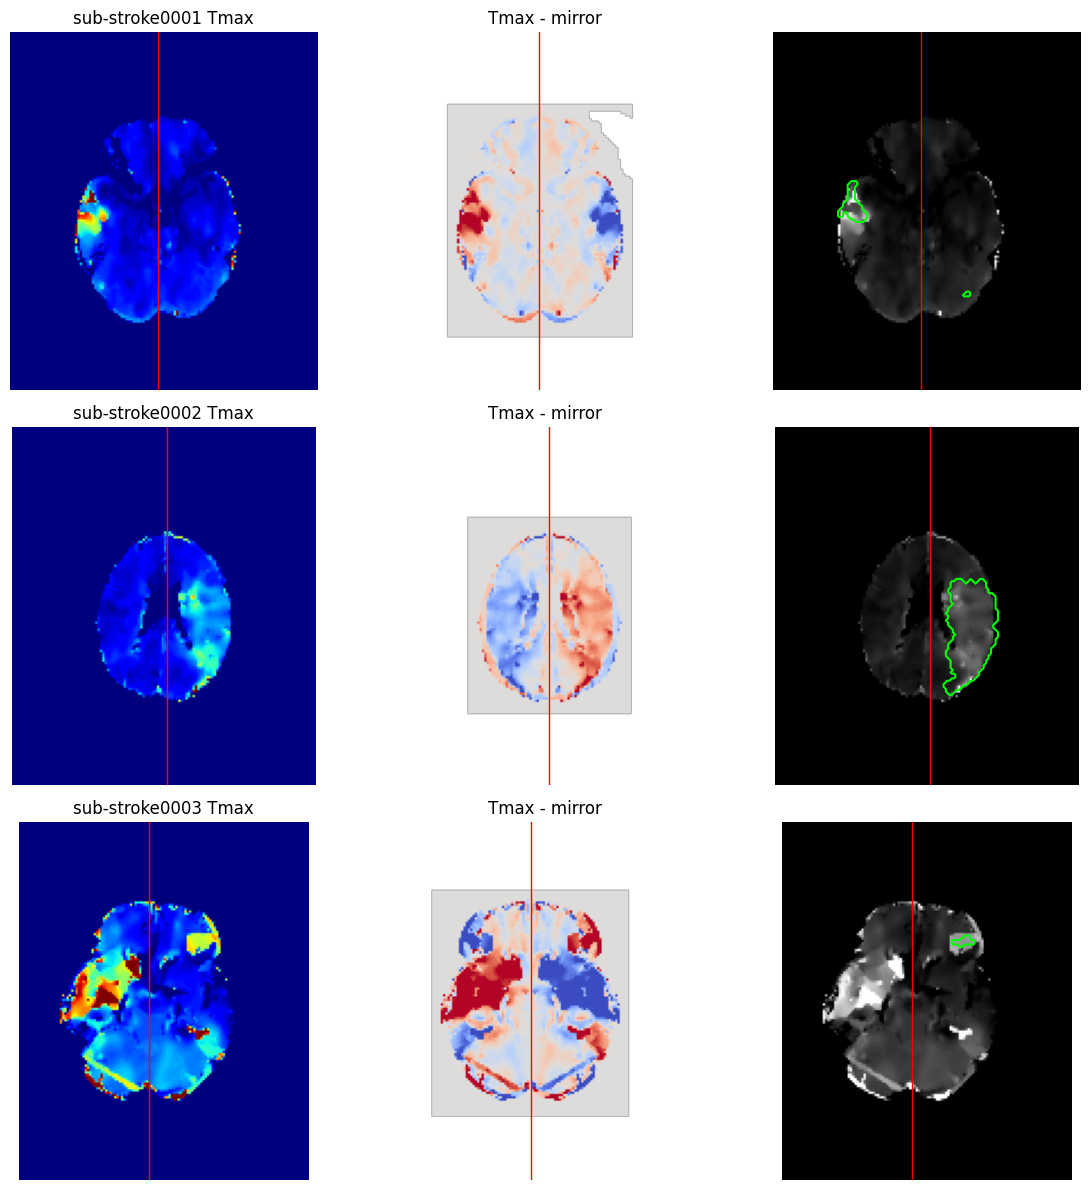

In [ ]:
def mirror_vol(v, mid):
    X = v.shape[0]; xm = np.rint(2 * mid - np.arange(X)).astype(int); ok = (xm >= 0) & (xm < X)
    out = np.full(v.shape, np.nan, np.float32); out[ok] = v[xm[ok]]; return out

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for r, sid in enumerate(IDS[:3]):
    p = get(sid); tm = p['arr'][3].astype(np.float32); z = int(np.argmax(p['mask'].sum(axis=(0, 1))))
    mv = mirror_vol(np.where(p['brain'], tm, np.nan), p['mid'])
    axes[r, 0].imshow(tm[:, :, z].T, cmap='jet', origin='lower'); axes[r, 0].set_title(f'{sid} Tmax')
    axes[r, 1].imshow((tm - mv)[:, :, z].T, cmap='coolwarm', origin='lower', vmin=-8, vmax=8); axes[r, 1].set_title('Tmax - mirror')
    axes[r, 2].imshow(tm[:, :, z].T, cmap='gray', origin='lower'); axes[r, 2].contour(p['mask'][:, :, z].T, colors='lime')
    for a in axes[r]: a.axvline(p['mid'], color='red', lw=1); a.axis('off')
plt.tight_layout(); plt.show()

## 3. Per-voxel interpretable features (never touches the lesion mask)
Every brain voxel gets ~35 features in five **groups** (used later for ablation + SHAP):
- `raw` — the four map values
- `relative` — value / whole-brain median (what "rCBF" means without needing the answer key; CBF is also divided by its 75th percentile, a reference that the non-brain voxels in the mask cannot drag down)
- `mirror` — value minus its mirror-image voxel across the midline, and mirror ratios (the "lopsided" signal)
- `context` — smoothed values, smoothed mirror differences, local Tmax variability
- `position` — distance from midline, front-back and up-down position (an anatomical prior; ablated later to check the model isn't just memorising anatomy)

In [ ]:
FEAT_GROUP = {}
def nsmooth(v, brain, s=(1.5, 1.5, 0.75)):
    w = ndi.gaussian_filter(brain.astype(np.float32), s)
    return ndi.gaussian_filter(np.where(brain, v, 0).astype(np.float32), s) / np.maximum(w, 1e-3)

def voxel_features(arr, brain, mid):
    arr = arr.astype(np.float32); cols, names = [], []
    def add(name, vol, group):
        cols.append(vol[brain]); names.append(name); FEAT_GROUP[name] = group
    for i, k in enumerate(MAPS):
        v = arr[i]; med = float(np.median(v[brain])) + 1e-6
        mv = mirror_vol(np.where(brain, v, np.nan), mid)
        add(f'raw_{k}', v, 'raw')
        add(f'rel_{k}', np.clip(v / med, 0, 20), 'relative')
        if k == 'cbf': add('relp75_cbf', np.clip(v / (float(np.percentile(v[brain], 75)) + 1e-6), 0, 20), 'relative')   # robust 'normal flow' reference
        add(f'mir_{k}', v - mv, 'mirror')
        if k in ('cbf', 'cbv'): add(f'mirratio_{k}', np.clip(v / (mv + 1e-3 * CAPS[k]), 0, 5), 'mirror')
        s = nsmooth(v, brain); sm = mirror_vol(np.where(brain, s, np.nan), mid)
        add(f'sm_{k}', s, 'context'); add(f'smmir_{k}', s - sm, 'context')
        if k == 'tmax':
            s2 = nsmooth(v * v, brain); add('lstd_tmax', np.sqrt(np.maximum(s2 - s * s, 0)), 'context')
    X, Y, Z = brain.shape
    ymin, ymax = find_extent(brain, (0, 2)); zs = np.nonzero(brain.any(axis=(0, 1)))[0]
    bc = lambda a, ax: np.broadcast_to(a.reshape([-1 if i == ax else 1 for i in range(3)]), brain.shape)
    add('pos_midline_dist', bc(np.abs(np.arange(X) - mid), 0), 'position')
    add('pos_front_back', bc((np.arange(Y) - ymin) / max(ymax - ymin, 1), 1), 'position')
    add('pos_up_down', bc((np.arange(Z) - zs.min()) / max(zs.max() - zs.min(), 1), 2), 'position')
    return np.stack(cols, 1).astype(np.float16), names, np.flatnonzero(brain)

FEAT = {}
for sid in tqdm(IDS):
    p = get(sid); F, names, bidx = voxel_features(p['arr'], p['brain'], p['mid'])
    FEAT[sid] = dict(F=F, y=p['mask'].reshape(-1)[bidx].astype(np.uint8), les_total=int(p['mask'].sum()),
                     vox_ml=p['vox_ml'], n=len(bidx))
    del p; gc.collect()
FEAT_NAMES = names; IDX = {n: i for i, n in enumerate(FEAT_NAMES)}; ALLC = list(range(len(FEAT_NAMES)))
print(len(FEAT_NAMES), 'features:', FEAT_NAMES)
print('feature RAM (GB):', round(sum(d['F'].nbytes for d in FEAT.values()) / 1e9, 2))
assert not any(n.startswith(('lesion', 'les_', 'reg_')) for n in FEAT_NAMES)   # leakage guard
ram('after features')

  0%|          | 0/147 [00:00<?, ?it/s]

27 features: ['raw_cbf', 'rel_cbf', 'relp75_cbf', 'mir_cbf', 'mirratio_cbf', 'sm_cbf', 'smmir_cbf', 'raw_cbv', 'rel_cbv', 'mir_cbv', 'mirratio_cbv', 'sm_cbv', 'smmir_cbv', 'raw_mtt', 'rel_mtt', 'mir_mtt', 'sm_mtt', 'smmir_mtt', 'raw_tmax', 'rel_tmax', 'mir_tmax', 'sm_tmax', 'smmir_tmax', 'lstd_tmax', 'pos_midline_dist', 'pos_front_back', 'pos_up_down']
feature RAM (GB): 3.32
[RAM after features] this notebook = 3.8 GB | machine has 7.6 GB free


## 4. Metric + the clinical-rule baselines
**Dice** is computed per patient against the *full* expert mask (lesion voxels outside the brain mask count as misses). Volume error = |predicted − true| mL.
`rule_tmax6` is the delayed-flow threshold; `rule_core` is the clinical "core" rule: very low flow (rCBF<30%) *inside* the delayed-flow region (Tmax>6 s). Two earlier versions applied the low-flow rule to the whole scan (against the brain median, then against the mirror-image voxel) and flagged ~45% of the tissue, because the brain mask includes non-brain tissue with noisy low values; restricting it to the delayed-flow region is also how the published clinical rule is defined. The first restricted version still divided by the brain median, which the non-brain voxels drag down, so it flagged almost nothing (~2 mL); it now divides by the 75th percentile of in-mask CBF as the 'normal flow' reference. `rule_best` tunes one feature + one threshold on training patients (the hardest simple opponent).

In [ ]:
def col(sid, name): return FEAT[sid]['F'][:, IDX[name]].astype(np.float32)

def score_pred(pred, sid):
    d = FEAT[sid]; tp = int((pred & (d['y'] == 1)).sum())
    return 2 * tp / (int(pred.sum()) + d['les_total'] + 1e-9), float(pred.sum()) * d['vox_ml']

RULES = {'rule_tmax6': lambda s: col(s, 'raw_tmax') > 6,
         'rule_core': lambda s: (col(s, 'raw_tmax') > 6) & (col(s, 'relp75_cbf') < 0.30)}   # clinical 'core': low flow (<30% of a robust normal-flow reference) INSIDE the delayed-flow region (Tmax>6 s)
CANDS = [('raw_tmax', 1), ('sm_tmax', 1), ('smmir_tmax', 1), ('mir_tmax', 1), ('rel_mtt', 1), ('rel_cbf', -1), ('relp75_cbf', -1), ('rel_cbv', -1)]

def fit_rule(train, max_eval=40, seed=0):
    rng = np.random.default_rng(seed); ev = list(rng.choice(train, min(max_eval, len(train)), replace=False))
    best = (-1, None)
    for name, s in CANDS:
        vals = {p: s * col(p, name) for p in ev}
        pooled = np.concatenate([v[::20] for v in vals.values()]); pooled = pooled[np.isfinite(pooled)]
        for t in np.unique(np.quantile(pooled, np.linspace(0.5, 0.99, 20))):
            dm = np.mean([score_pred(vals[p] > t, p)[0] for p in ev])
            if dm > best[0]: best = (dm, (name, s, float(t)))
    return best[1]

def rule_pred(rule, sid): name, s, t = rule; return (s * col(sid, name)) > t

rd = pd.DataFrame({k: [score_pred(f(s), s)[0] for s in IDS] for k, f in RULES.items()}, index=IDS)
print('Fixed clinical rules, mean Dice over all patients (no training involved):'); print(rd.mean().round(3).to_string())

Fixed clinical rules, mean Dice over all patients (no training involved):
rule_tmax6    0.135
rule_core     0.097


In [ ]:
rows = []
for s in IDS:
    d = FEAT[s]; vm = d['vox_ml']
    rows.append(dict(brain_mL=d['n'] * vm, pct_brain_with_zero_CBF=100 * float(np.mean(col(s, 'raw_cbf') == 0)), true_lesion_mL=d['les_total'] * vm,
                     tmax6_flags_mL=float(RULES['rule_tmax6'](s).sum()) * vm, core_flags_mL=float(RULES['rule_core'](s).sum()) * vm))
D = pd.DataFrame(rows, index=IDS); print('--- Sanity check on the clinical rules (per-patient averages) ---')
print(D.describe().loc[['mean', '50%', 'min', 'max']].round(1).to_string())
print('A real adult brain is roughly 1,100-1,400 mL. If core_flags_mL is a large share of brain_mL, the rule is flagging non-brain or empty voxels, not damaged tissue. It should be a modest number (tens to a couple of hundred mL).')

--- Sanity check on the clinical rules (per-patient averages) ---
      brain_mL  pct_brain_with_zero_CBF  true_lesion_mL  tmax6_flags_mL  core_flags_mL
mean    2671.2                      0.2            31.9           157.3           14.8
50%     2306.1                      0.0            13.3           142.4            9.5
min     1173.4                      0.0             0.0            14.4            0.2
max     4508.0                      7.9           220.0           436.1          132.0
A real adult brain is roughly 1,100-1,400 mL. If core_flags_mL is a large share of brain_mL, the rule is flagging non-brain or empty voxels, not damaged tissue. It should be a modest number (tens to a couple of hundred mL).


## 5. Contestant A — interpretable gradient boosting (XGBoost on voxel features)
Training voxels: up to 2,500 lesion + 2,500 random non-lesion voxels per training patient. **Same tuning budget as the U-Net:** 2 hyper-parameter settings, one patient-level validation split (20% of training patients), and a probability threshold chosen to maximise validation Dice. No refit: the model that won on the validation patients is the one that is scored (same rule for the U-Net).

In [ ]:
import xgboost as xgb
GBM_GRID = [dict(max_depth=d, n_estimators=300) for d in (3, 5)]
if QUICK: GBM_GRID = GBM_GRID[:2]

def sample_train(pids, rng, npos=2500, nneg=2500):
    Xs, ys = [], []
    for p in pids:
        d = FEAT[p]; y = d['y']; ip, ineg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
        if len(ip): ip = rng.choice(ip, min(npos, len(ip)), replace=False)
        ineg = rng.choice(ineg, min(nneg, len(ineg)), replace=False); idx = np.concatenate([ip, ineg])
        Xs.append(d['F'][idx]); ys.append(y[idx])
    return np.concatenate(Xs).astype(np.float32), np.concatenate(ys)

def predict_p(model, sid, cols): return model.predict_proba(FEAT[sid]['F'][:, cols].astype(np.float32))[:, 1]

def sweep_thr(probs, pids, dicefn):
    sc = [np.mean([dicefn(probs[s], t, s) for s in pids]) for t in THR]; i = int(np.argmax(sc)); return float(THR[i]), float(sc[i])

gbm_dice = lambda p, t, s: score_pred(p > t, s)[0]

def make_xgb(h, seed): return xgb.XGBClassifier(**h, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                                                 n_jobs=-1, random_state=seed, eval_metric='logloss')

def fit_gbm(train, seed=0, hp=None, cols=None):
    cols = cols or ALLC; rng = np.random.default_rng(seed); tp = list(rng.permutation(train))
    nv = max(3, int(0.2 * len(tp))); val, fit = tp[:nv], tp[nv:]
    X, y = sample_train(fit, rng); best = None
    for h in ([hp] if hp else GBM_GRID):
        m = make_xgb(h, seed).fit(X[:, cols], y); pv = {s: predict_p(m, s, cols) for s in val}
        thr, dv = sweep_thr(pv, val, gbm_dice)
        if best is None or dv > best[0]: best = (dv, thr, h, m)
    if not REFIT: return dict(model=best[3], thr=best[1], hp=best[2], cols=cols)
    X, y = sample_train(list(train), rng)
    return dict(model=make_xgb(best[2], seed).fit(X[:, cols], y), thr=best[1], hp=best[2], cols=cols)

## 6. Contestant B — small U-Net (the foil), in two fair versions
- `unet_raw`: the 4 raw maps (what a standard black-box would see).
- `unet_mirror`: the 4 maps **plus** their mirror differences (the network is handed the same lopsidedness idea). If the simple model still matches this one, the claim is much stronger.

Slices are cropped to a square **centred on the midline**, so the mirror image is just a horizontal flip. Same tuning budget: 2 settings (short vs long training), 20% validation patients, Dice-tuned threshold, no refit (trained on 80% of the training patients, like the simple model). Mirror-flip augmentation is used (valid: a flipped brain with a flipped lesion is a new valid example). Loss = BCE + soft Dice, computed inside the brain mask only.

In [ ]:
import torch, torch.nn as nn
dev = 'cuda' if torch.cuda.is_available() else 'cpu'; print('device:', dev)
if dev == 'cpu' and not QUICK: print('WARNING: no GPU. Runtime > Change runtime type > T4 GPU. CPU will be very slow.')

# square crop size from the data (multiple of 16), centred on the midline
HAVE_GPU = torch.cuda.is_available(); BUILD_UNET = HAVE_GPU or QUICK      # on a CPU-only runtime the U-Nets are skipped (saves RAM and Colab compute units)
ext = []
for s in (IDS if BUILD_UNET else []):
    b, mid = get(s)['brain'], P[s]['mid']; xmin, xmax = find_extent(b, (1, 2)); ymin, ymax = find_extent(b, (0, 2))
    ext.append(max(2 * max(mid - xmin, xmax - mid), ymax - ymin))
SIDE = int(16 * math.ceil((max(ext) + 4) / 16)) if ext else 144; print('U-Net crop side:', SIDE)

def crop_vol(a, mid, ymid, S):                    # (X,Y,Z) -> (Z,S,S); axis1 = x (left->right), axis2 = y
    x0, y0 = int(round(mid - (S - 1) / 2)), int(round(ymid - (S - 1) / 2))
    out = np.zeros((a.shape[2], S, S), a.dtype)
    xs0, ys0, xs1, ys1 = max(x0, 0), max(y0, 0), min(x0 + S, a.shape[0]), min(y0 + S, a.shape[1])
    if xs1 > xs0 and ys1 > ys0: out[:, xs0 - x0:xs1 - x0, ys0 - y0:ys1 - y0] = np.moveaxis(a[xs0:xs1, ys0:ys1, :], 2, 0)
    return out

LO = 1      # extra U-Net downsampling (1 = none; the DS=4 grid is already coarse). Kept as a knob if the GPU job is too slow.
def pool(a, how):                                  # (Z,S,S) -> (Z,S/LO,S/LO)
    Z, S, _ = a.shape; v = a.astype(np.float32).reshape(Z, S // LO, LO, S // LO, LO)
    return v.mean(axis=(2, 4)) if how == 'mean' else v.max(axis=(2, 4))
UD = {}
for s in (IDS if BUILD_UNET else []):
    p = get(s); ymin, ymax = find_extent(p['brain'], (0, 2)); ym = (ymin + ymax) / 2
    xs = np.stack([crop_vol(p['arr'][c], p['mid'], ym, SIDE) for c in range(4)], 1).astype(np.float32)          # (Z,4,S,S)
    Zn = xs.shape[0]; xlo = xs.reshape(Zn, 4, SIDE // LO, LO, SIDE // LO, LO).mean(axis=(3, 5)).astype(np.float16)
    br, mk = crop_vol(p['brain'], p['mid'], ym, SIDE), crop_vol(p['mask'], p['mid'], ym, SIDE)
    UD[s] = dict(x=xlo, brain=br, mask=mk, brain_lo=(br if LO == 1 else pool(br, 'mean') >= 0.5), mask_lo=(mk if LO == 1 else pool(mk, 'max') > 0.5))
    del p, xs, xlo; gc.collect()
print('U-Net input grid:', SIDE // LO, 'x', SIDE // LO); ram('after U-Net tensors')
gc.collect(); ram('after freeing raw arrays')
CAPV = torch.tensor([CAPS[k] for k in MAPS], dtype=torch.float32, device=dev).view(1, 4, 1, 1)

def cb(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                   nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
class UNet(nn.Module):
    def __init__(s, cin=4, w=16):
        super().__init__(); s.pool = nn.MaxPool2d(2)
        s.e1, s.e2, s.e3, s.b = cb(cin, w), cb(w, 2 * w), cb(2 * w, 4 * w), cb(4 * w, 8 * w)
        s.u3, s.d3 = nn.ConvTranspose2d(8 * w, 4 * w, 2, 2), cb(8 * w, 4 * w)
        s.u2, s.d2 = nn.ConvTranspose2d(4 * w, 2 * w, 2, 2), cb(4 * w, 2 * w)
        s.u1, s.d1 = nn.ConvTranspose2d(2 * w, w, 2, 2), cb(2 * w, w); s.out = nn.Conv2d(w, 1, 1)
    def forward(s, x):
        e1 = s.e1(x); e2 = s.e2(s.pool(e1)); e3 = s.e3(s.pool(e2)); b = s.b(s.pool(e3))
        d3 = s.d3(torch.cat([s.u3(b), e3], 1)); d2 = s.d2(torch.cat([s.u2(d3), e2], 1)); d1 = s.d1(torch.cat([s.u1(d2), e1], 1))
        return s.out(d1)
UNET_PARAMS = {'unet_raw': sum(p.numel() for p in UNet(4).parameters()), 'unet_mirror': sum(p.numel() for p in UNet(8).parameters())}
print('U-Net parameters:', UNET_PARAMS)

UNET_GRID = [dict(lr=3e-3, epochs=e) for e in (12, 24)]
if QUICK: UNET_GRID = [dict(lr=3e-3, epochs=2)]
def prep(xb, variant): return torch.cat([xb, xb - xb.flip(2)], 1) if variant == 'unet_mirror' else xb

def assemble(pids):
    Xs, Ys, Bs = [], [], []
    for p in pids:                              # move each patient's slices to the GPU one at a time (no large host-side copy)
        u = UD[p]; k = u['brain_lo'].reshape(len(u['brain_lo']), -1).sum(1) >= max(1, 50 // (LO * LO))
        Xs.append(torch.from_numpy(u['x'][k]).to(dev)); Ys.append(torch.from_numpy(u['mask_lo'][k]).to(dev)); Bs.append(torch.from_numpy(u['brain_lo'][k]).to(dev))
    return torch.cat(Xs), torch.cat(Ys), torch.cat(Bs)

def train_unet(pids, variant, lr, epochs, seed=0, bs=32):
    torch.manual_seed(seed); X, Y, B = assemble(pids); net = UNet(8 if variant == 'unet_mirror' else 4).to(dev)
    opt = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-4)
    f = Y.float().mean().item(); pw = torch.tensor(min(10.0, max(1.0, ((1 - f) / max(f, 1e-4)) ** 0.5)), device=dev)
    for ep in range(epochs):
        net.train(); perm = torch.randperm(len(X), device=dev)
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]; xb, yb, bm = X[idx].float() / CAPV, Y[idx].float(), B[idx].float()
            fl = torch.rand(len(idx), device=dev) < 0.5                       # mirror augmentation
            xb = torch.where(fl[:, None, None, None], xb.flip(2), xb)
            yb = torch.where(fl[:, None, None], yb.flip(1), yb); bm = torch.where(fl[:, None, None], bm.flip(1), bm)
            lg = net(prep(xb, variant)).squeeze(1)
            bce = (nn.functional.binary_cross_entropy_with_logits(lg, yb, reduction='none', pos_weight=pw) * bm).sum() / bm.sum().clamp(min=1)
            pr = torch.sigmoid(lg) * bm; dl = 1 - (2 * (pr * yb).sum() + 1) / (pr.sum() + yb.sum() + 1)
            opt.zero_grad(); (bce + dl).backward(); opt.step()
    del X, Y, B;
    if dev == 'cuda': torch.cuda.empty_cache()
    return net

@torch.no_grad()
def unet_probs(net, variant, sid):
    net.eval(); x = torch.tensor(UD[sid]['x']).to(dev).float() / CAPV
    return torch.cat([torch.sigmoid(net(prep(x[i:i + 64], variant))).squeeze(1) for i in range(0, len(x), 64)]).cpu().numpy()

def unet_dice_vol(prob, thr, sid):
    u = UD[sid]; up = prob.repeat(LO, axis=1).repeat(LO, axis=2); pred = (up > thr) & u['brain']; tp = int((pred & u['mask']).sum()); n = int(pred.sum())
    return 2 * tp / (n + FEAT[sid]['les_total'] + 1e-9), n * FEAT[sid]['vox_ml']
unet_dice = lambda p, t, s: unet_dice_vol(p, t, s)[0]

def fit_unet(train, variant, seed=0, hp=None):
    rng = np.random.default_rng(seed); tp = list(rng.permutation(train)); nv = max(3, int(0.2 * len(tp))); val, fit = tp[:nv], tp[nv:]
    best = None
    for h in ([hp] if hp else UNET_GRID):
        net = train_unet(fit, variant, h['lr'], h['epochs'], seed); pv = {s: unet_probs(net, variant, s) for s in val}
        thr, dv = sweep_thr(pv, val, unet_dice)
        if best is None or dv > best[0]: best = (dv, thr, h, net)
    if not REFIT: return dict(net=best[3], thr=best[1], hp=best[2], variant=variant)
    return dict(net=train_unet(list(train), variant, best[2]['lr'], best[2]['epochs'], seed), thr=best[1], hp=best[2], variant=variant)

device: cpu
U-Net crop side: 144
U-Net input grid: 144 x 144
[RAM after U-Net tensors] this notebook = 3.9 GB | machine has 7.5 GB free
[RAM after freeing raw arrays] this notebook = 3.9 GB | machine has 7.5 GB free
U-Net parameters: {'unet_raw': 483585, 'unet_mirror': 484161}


## 7. One interface for every model, then the MAIN experiment
`run_model` trains on `train`, scores `test`, and records Dice, predicted vs true lesion volume, training time, inference time, model size. 5 patient-level folds (the same `folds.csv` for everyone).

In [ ]:
def run_model(name, train, test, seed=0, hp=None):
    t0 = time.time(); info = {'name': name}; rows = []
    if name in RULES: info['train_s'] = 0.0; pf = lambda s: RULES[name](s)
    elif name == 'rule_best':
        rule = fit_rule(train, seed=seed); info.update(train_s=time.time() - t0, hp=rule); pf = lambda s: rule_pred(rule, s)
    elif name == 'xgb':
        M = fit_gbm(train, seed, hp); info.update(train_s=time.time() - t0, hp=M['hp'], model=M,
                                                  size_kb=len(M['model'].get_booster().save_raw()) / 1024)
        pf = lambda s: predict_p(M['model'], s, M['cols']) > M['thr']
    else:
        M = fit_unet(train, name, seed, hp); info.update(train_s=time.time() - t0, hp=M['hp'], params=UNET_PARAMS[name],
                                                         size_kb=UNET_PARAMS[name] * 4 / 1024, model=M)
        pf = None
    for s in test:
        t1 = time.time()
        if pf is not None: d, v = score_pred(pf(s), s)
        else: d, v = unet_dice_vol(unet_probs(M['net'], name, s), M['thr'], s)
        rows.append(dict(subject_id=s, dice=d, vol_pred=v, vol_true=FEAT[s]['les_total'] * FEAT[s]['vox_ml'], infer_s=time.time() - t1))
    return rows, info

ALLMODELS = ['rule_tmax6', 'rule_core', 'rule_best', 'xgb'] + (['unet_raw', 'unet_mirror'] if HAVE_GPU else [])
print('Models in this run:', ALLMODELS)
if not HAVE_GPU: print('CPU-ONLY RUN: the U-Nets are skipped. Everything finished here is saved. To add the U-Nets later: switch the runtime to T4 GPU and re-run from the top; finished models are not recomputed.')
CK = os.path.join(PROJECT, f'ck_main_{NB_VER}_ds{DS}' + ('_quick' if QUICK else '') + '.pkl')      # saved after EVERY model/fold: a Colab disconnect costs minutes, not hours
ck = pickle.load(open(CK, 'rb')) if os.path.exists(CK) else dict(MAIN=[], COST=[], HPLOG={m: [] for m in ALLMODELS}, done=set())
MAIN, COST, HPLOG, DONE = ck['MAIN'], ck['COST'], ck['HPLOG'], ck['done']
for f in FOLDS_TO_RUN:
    tr = [s for s in IDS if FOLD[s] != f]; te = [s for s in IDS if FOLD[s] == f]
    for name in ALLMODELS:
        if (f, name) in DONE: continue
        t_start = time.time(); rows, info = run_model(name, tr, te, SEED)
        for r in rows: r.update(model=name, exp='main', fold=f)
        MAIN += rows; HPLOG.setdefault(name, []).append(info.get('hp'))
        COST.append(dict(model=name, fold=f, train_s=info['train_s'], size_kb=info.get('size_kb'), params=info.get('params'),
                         infer_ms=1000 * np.mean([r['infer_s'] for r in rows])))
        DONE.add((f, name)); pickle.dump(dict(MAIN=MAIN, COST=COST, HPLOG=HPLOG, done=DONE), open(CK, 'wb'))
        print(f'fold {f} | {name:12s} | mean Dice {np.mean([r["dice"] for r in rows]):.3f} | {time.time() - t_start:.0f}s')
        if name in ('xgb', 'unet_raw', 'unet_mirror'): ram(f'fold {f} {name}')
main = pd.DataFrame(MAIN); cost = pd.DataFrame(COST)

def mode_hp(m):
    hs = [h for h in HPLOG.get(m, []) if h is not None]
    return dict(Counter(tuple(sorted(h.items())) for h in hs).most_common(1)[0][0]) if hs and isinstance(hs[0], dict) else None
BEST_HP = {m: mode_hp(m) for m in ('xgb', 'unet_raw', 'unet_mirror')}; print('hyper-parameters reused in size/site sweeps:', BEST_HP)
with open(RESULTS, 'wb') as fh: pickle.dump(dict(main=main, cost=cost, BEST_HP=BEST_HP), fh)

Models in this run: ['rule_tmax6', 'rule_core', 'rule_best', 'xgb']
CPU-ONLY RUN: the U-Nets are skipped. Everything finished here is saved. To add the U-Nets later: switch the runtime to T4 GPU and re-run from the top; finished models are not recomputed.
hyper-parameters reused in size/site sweeps: {'xgb': {'max_depth': 5, 'n_estimators': 300}, 'unet_raw': {'epochs': 24, 'lr': 0.003}, 'unet_mirror': {'epochs': 12, 'lr': 0.003}}


## 8. Head-to-head with proper statistics
Paired bootstrap over **patients** of the Dice difference (simple − deep). Verdicts use the pre-registered margin: *interval inside ±DELTA* = equivalent; *lower bound above −DELTA* = non-inferior; interval containing 0 alone is **not** called equivalence.

In [ ]:
def paired_ci(a, b, n=2000, seed=0):
    rng = np.random.default_rng(seed); d = (a - b).values; k = len(d)
    bs = [d[rng.integers(0, k, k)].mean() for _ in range(n)]; lo, hi = np.percentile(bs, [2.5, 97.5]); return d.mean(), lo, hi

def verdict(lo, hi, delta=DELTA):
    if lo > delta: return 'SIMPLE BETTER (> +delta)'
    if lo > -delta and hi < delta: return 'EQUIVALENT (CI inside +/-delta)'
    if lo > -delta: return 'NON-INFERIOR (simple >= deep - delta)'
    if hi < -delta: return 'SIMPLE WORSE (< -delta)'
    return 'INCONCLUSIVE'

def pat_dice(df, model): return df[df['model'] == model].groupby('subject_id')['dice'].mean()

print('=== MAIN EXPERIMENT: Dice (mean over patients; sd of the 5 fold means) ===')
summ = main.groupby(['model', 'fold'])['dice'].mean().groupby('model').agg(['mean', 'std'])
summ['median_patient_dice'] = main.groupby('model')['dice'].median()
summ['mean_abs_vol_err_mL'] = main.assign(e=(main.vol_pred - main.vol_true).abs()).groupby('model')['e'].mean()
print(summ.loc[ALLMODELS].round(3).to_string())

print('\n=== xgb vs deep: paired bootstrap of Dice difference, margin +/-', DELTA, '===')
for deep in [d for d in ('unet_raw', 'unet_mirror') if d in set(main.model)]:
    m, lo, hi = paired_ci(pat_dice(main, 'xgb'), pat_dice(main, deep)); print(f'xgb - {deep:12s} {m:+.3f} [{lo:+.3f}, {hi:+.3f}]  -> {verdict(lo, hi)}')
for r in ('rule_tmax6', 'rule_core', 'rule_best'):
    m, lo, hi = paired_ci(pat_dice(main, 'xgb'), pat_dice(main, r)); print(f'xgb - {r:12s} {m:+.3f} [{lo:+.3f}, {hi:+.3f}]')

print('\n=== COMPUTE COST (mean per fold; xgb/rules on CPU, U-Net on', dev, ') ===')
print(cost.groupby('model')[['train_s', 'size_kb', 'params', 'infer_ms']].mean().loc[ALLMODELS].round(1).to_string())

=== MAIN EXPERIMENT: Dice (mean over patients; sd of the 5 fold means) ===
             mean    std  median_patient_dice  mean_abs_vol_err_mL
model                                                             
rule_tmax6  0.135  0.013                0.073              130.220
rule_core   0.097  0.017                0.022               24.405
rule_best   0.173  0.020                0.099               65.547
xgb         0.207  0.018                0.146               40.580

=== xgb vs deep: paired bootstrap of Dice difference, margin +/- 0.05 ===
xgb - unet_raw     +0.015 [-0.005, +0.035]  -> EQUIVALENT (CI inside +/-delta)
xgb - unet_mirror  +0.011 [-0.008, +0.030]  -> EQUIVALENT (CI inside +/-delta)
xgb - rule_tmax6   +0.072 [+0.055, +0.089]
xgb - rule_core    +0.110 [+0.089, +0.132]
xgb - rule_best    +0.034 [+0.019, +0.049]

=== COMPUTE COST (mean per fold; xgb/rules on CPU, U-Net on cpu ) ===
            train_s  size_kb  params  infer_ms
model                                      

## 9. THE HEADLINE EXPERIMENT — data-efficiency curve
Train on only *n* patients (n = 10, 20, 40, 80, all) and test on the same held-out fold patients every time. Hyper-parameters are fixed to the values chosen in the main run (identically for both families); the Dice threshold is still tuned on a validation split. Small n is repeated over 2 seeds. **Question: does the deep model ever overtake the simple one, and at what n?**

size/shift sweeps use the stronger U-Net: unet_mirror
fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done


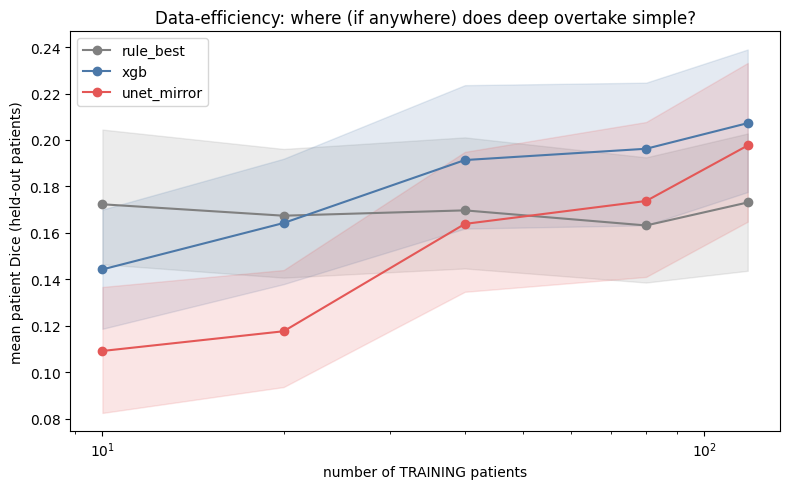

xgb - deep, paired bootstrap per training size (positive = simple ahead):
n=  10 vs unet_mirror  +0.035 [+0.014, +0.058]  NON-INFERIOR (simple >= deep - delta)
n=  20 vs unet_mirror  +0.047 [+0.025, +0.069]  NON-INFERIOR (simple >= deep - delta)
n=  40 vs unet_mirror  +0.028 [+0.007, +0.050]  EQUIVALENT (CI inside +/-delta)
n=  80 vs unet_mirror  +0.022 [+0.004, +0.041]  EQUIVALENT (CI inside +/-delta)
n= 118 vs unet_mirror  +0.010 [-0.010, +0.031]  EQUIVALENT (CI inside +/-delta)

Other pairs per training size (a CI that excludes 0 = a real difference):
n=  10 xgb - rule_best    -0.028 [-0.046, -0.011]  -> xgb is behind
n=  10 unet_mirror - rule_best    -0.063 [-0.086, -0.042]  -> unet_mirror is behind
n=  10 xgb - unet_mirror  +0.035 [+0.014, +0.058]  -> xgb is ahead
n=  20 xgb - rule_best    -0.003 [-0.018, +0.011]  -> xgb is tied (CI includes 0)
n=  20 unet_mirror - rule_best    -0.050 [-0.077, -0.025]  -> unet_mirror is behind
n=  20 xgb - unet_mirror  +0.047 [+0.025, +0.069]  -> 

In [ ]:
N_LIST = [5, 10, None] if QUICK else [10, 20, 40, 80, None]
have_unet = [m for m in ('unet_raw', 'unet_mirror') if m in set(main.model)]
best_unet = max(have_unet, key=lambda m: main[main.model == m]['dice'].mean()) if have_unet else None      # the STRONGER foil is the one used in the sweeps (fairest to the deep side)
DE_MODELS = ['rule_best', 'xgb'] + ([best_unet] if best_unet else []); SEEDS_SMALL = (0,)       # add a second seed (0, 1) only if time allows
print('size/shift sweeps use the stronger U-Net:', best_unet if best_unet else 'NONE YET (no U-Net results; run on a GPU runtime to add them)')
CKD = os.path.join(PROJECT, f'ck_de_{NB_VER}_ds{DS}' + ('_quick' if QUICK else '') + '.pkl')
ckd = pickle.load(open(CKD, 'rb')) if os.path.exists(CKD) else dict(DE=[], done=set())
DE, DONE_DE = ckd['DE'], ckd['done']
for f in FOLDS_TO_RUN:
    tr_all = [s for s in IDS if FOLD[s] != f]; te = [s for s in IDS if FOLD[s] == f]
    for n in N_LIST:
        if n is not None and n >= len(tr_all): continue
        for seed in (SEEDS_SMALL if n is not None else (0,)):
            rng = np.random.default_rng(100 * seed + f); tr = tr_all if n is None else list(rng.choice(tr_all, n, replace=False))
            for name in DE_MODELS:
                key = (f, n, seed, name)
                if key in DONE_DE: continue
                rows, _ = run_model(name, tr, te, seed, hp=BEST_HP.get(name))
                for r in rows: r.update(model=name, exp='de', fold=f, n_train=(n if n is not None else -1), seed=seed, n_actual=len(tr))
                DE += rows; DONE_DE.add(key); pickle.dump(dict(DE=DE, done=DONE_DE), open(CKD, 'wb'))
    print('fold', f, 'done')
de = pd.DataFrame(DE)
with open(RESULTS, 'wb') as fh: pickle.dump(dict(main=main, cost=cost, BEST_HP=BEST_HP, de=de), fh)

de['n_lab'] = de['n_train'].replace(-1, int(de['n_actual'].max()))
curve = de.groupby(['model', 'n_lab', 'subject_id'])['dice'].mean().reset_index()
fig, ax = plt.subplots(figsize=(8, 5)); rng = np.random.default_rng(0)
for m, c in zip(DE_MODELS, ['gray', '#4C78A8', '#E45756', '#B279A2']):
    xs, ms, los, his = [], [], [], []
    for n, g in curve[curve['model'] == m].groupby('n_lab'):
        v = g['dice'].values; bs = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(500)]
        xs.append(n); ms.append(v.mean()); los.append(np.percentile(bs, 2.5)); his.append(np.percentile(bs, 97.5))
    ax.plot(xs, ms, 'o-', color=c, label=m); ax.fill_between(xs, los, his, color=c, alpha=0.15)
ax.set_xscale('log'); ax.set_xlabel('number of TRAINING patients'); ax.set_ylabel('mean patient Dice (held-out patients)')
ax.set_title('Data-efficiency: where (if anywhere) does deep overtake simple?'); ax.legend(); plt.tight_layout(); plt.show()

print('xgb - deep, paired bootstrap per training size (positive = simple ahead):')
for n in sorted(curve['n_lab'].unique()):
    for deep in ([best_unet] if best_unet else []):
        a = curve[(curve.model == 'xgb') & (curve.n_lab == n)].set_index('subject_id')['dice']
        b = curve[(curve.model == deep) & (curve.n_lab == n)].set_index('subject_id')['dice']; k = a.index.intersection(b.index)
        m, lo, hi = paired_ci(a[k], b[k]); print(f'n={n:4d} vs {deep:12s} {m:+.3f} [{lo:+.3f}, {hi:+.3f}]  {verdict(lo, hi)}')

print('\nOther pairs per training size (a CI that excludes 0 = a real difference):')
PAIRS = [('xgb', 'rule_best')] + ([(best_unet, 'rule_best'), ('xgb', best_unet)] if best_unet else [])
for n in sorted(curve['n_lab'].unique()):
    for p1, p2 in PAIRS:
        a = curve[(curve.model == p1) & (curve.n_lab == n)].set_index('subject_id')['dice']
        b = curve[(curve.model == p2) & (curve.n_lab == n)].set_index('subject_id')['dice']; k = a.index.intersection(b.index)
        m, lo, hi = paired_ci(a[k], b[k]); lab = 'ahead' if lo > 0 else ('behind' if hi < 0 else 'tied (CI includes 0)')
        print(f'n={n:4d} {p1} - {p2:12s} {m:+.3f} [{lo:+.3f}, {hi:+.3f}]  -> {p1} is {lab}')

## 10. Optional: does it survive a change in image resolution?
The dataset has **no hospital/center column**, so this is *not* a hospital test. As a weak stand-in for "different scanner/protocol", patients are split by in-plane pixel size (finer vs coarser than the median). Models train on one half and are tested on the other (both directions). **Caveat:** each model trains on about half the patients here, so compare the result with the n = 80 point of the data-efficiency curve, not with the full-data score. Report it as an *image-resolution shift check*, never as a site test.

In [ ]:
SP = {s: META[s]['zooms'][0] for s in IDS}; MED_SP = float(np.median(list(SP.values())))
def site_of(s):
    m = META[s]
    if SITE_COL and m.get(SITE_COL) is not None: return str(m[SITE_COL])
    return 'finer_pixels' if SP[s] <= MED_SP else 'coarser_pixels'
SITE = {s: site_of(s) for s in IDS}; vc = pd.Series(SITE).value_counts(); print('groups:', 'REAL SITE' if SITE_COL else 'IMAGE-RESOLUTION SPLIT (not a hospital split)'); print(vc.to_string())
big = [g for g, c in vc.items() if c >= (4 if QUICK else 8)]
CKL = os.path.join(PROJECT, f'ck_loso_{NB_VER}_ds{DS}' + ('_quick' if QUICK else '') + '.pkl')
ckl = pickle.load(open(CKL, 'rb')) if os.path.exists(CKL) else dict(LOSO=[], done=set())
LOSO, DONE_LO = ckl['LOSO'], ckl['done']
if len(big) < 2:
    print('Fewer than 2 usable groups -> leave-one-site-out is not possible on this data. Report the flipped-orientation robustness check instead.')
else:
    for g in big:
        te = [s for s in IDS if SITE[s] == g]; tr = [s for s in IDS if SITE[s] != g]
        for name in DE_MODELS:
            if (g, name) in DONE_LO: continue
            rows, _ = run_model(name, tr, te, SEED, hp=BEST_HP.get(name))
            for r in rows: r.update(model=name, exp='loso', site=g)
            LOSO += rows; DONE_LO.add((g, name)); pickle.dump(dict(LOSO=LOSO, done=DONE_LO), open(CKL, 'wb'))
        print('held out', g, 'n =', len(te))
    loso = pd.DataFrame(LOSO); ref = main[main.model.isin(DE_MODELS)].groupby(['model', 'subject_id'])['dice'].mean().rename('dice_random_fold')
    gap = loso.merge(ref.reset_index(), on=['model', 'subject_id'])
    g2 = gap.groupby('model').agg(dice_new_site=('dice', 'mean'), dice_random_fold=('dice_random_fold', 'mean'))
    g2['drop'] = g2['dice_random_fold'] - g2['dice_new_site']; print('\n=== Generalisation gap when the site/protocol is unseen ==='); print(g2.round(3).to_string())
    with open(RESULTS, 'wb') as fh: pickle.dump(dict(main=main, cost=cost, BEST_HP=BEST_HP, de=de, loso=loso), fh)

groups: IMAGE-RESOLUTION SPLIT (not a hospital split)
finer_pixels      97
coarser_pixels    50
held out finer_pixels n = 97
held out coarser_pixels n = 50

=== Generalisation gap when the site/protocol is unseen ===
             dice_new_site  dice_random_fold   drop
model                                              
rule_best            0.162             0.173  0.011
unet_mirror          0.163             0.197  0.033
xgb                  0.168             0.207  0.039


## 11. Failure map — where and why the simple model breaks
Dice by lesion-size quartile, by whether the damage reaches the posterior third of the brain, and for lesions that cross the midline (descriptors from the Week-2 table; they are used only for *grouping results*, never as model inputs).

=== mean Dice by lesion-size quartile ===
model        rule_best  unet_mirror  unet_raw    xgb
size_q                                              
Q1 smallest      0.020        0.032     0.048  0.050
Q2               0.105        0.134     0.118  0.131
Q3               0.177        0.226     0.196  0.238
Q4 largest       0.396        0.390     0.405  0.410


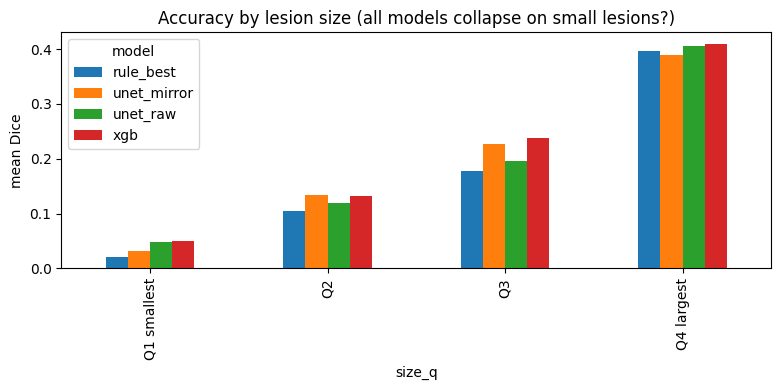


=== by posterior involvement ===
model                    rule_best  unet_mirror  unet_raw    xgb
posterior                                                       
no posterior damage          0.112        0.154     0.150  0.165
reaches posterior third      0.237        0.241     0.236  0.251

=== by bilateral (>=10% of lesion on other side) ===
                      mean                                count                          
model            rule_best unet_mirror unet_raw   xgb rule_best unet_mirror unet_raw  xgb
lesion_bilateral                                                                         
0                    0.194       0.222    0.216  0.23       126         126      126  126
1                    0.047       0.046    0.048  0.07        21          21       21   21

Simple-vs-deep gap (xgb - unet_mirror) per size quartile:
size_q
Q1 smallest    0.018
Q2            -0.002
Q3             0.012
Q4 largest     0.020


In [ ]:
desc = pd.read_csv(FEATS_V2) if os.path.exists(FEATS_V2) else pd.DataFrame({'subject_id': IDS})
keep = [c for c in ('subject_id', 'lesion_ml', 'lesion_bilateral', 'lesion_mid_dist_mm', 'reg_L_post', 'reg_R_post') if c in desc.columns]
fm = main[main.model.isin(['rule_best', 'xgb', 'unet_raw', 'unet_mirror'])].merge(desc[keep], on='subject_id', how='left')
fm['lesion_ml'] = fm['vol_true'] if 'lesion_ml' not in fm else fm['lesion_ml'].fillna(fm['vol_true'])
fm['size_q'] = pd.qcut(fm['vol_true'].rank(method='first'), 4, labels=['Q1 smallest', 'Q2', 'Q3', 'Q4 largest'])
tabq = fm.pivot_table(index='size_q', columns='model', values='dice', aggfunc='mean'); print('=== mean Dice by lesion-size quartile ==='); print(tabq.round(3).to_string())
ax = tabq.plot(kind='bar', figsize=(8, 4)); ax.set_ylabel('mean Dice'); ax.set_title('Accuracy by lesion size (all models collapse on small lesions?)'); plt.tight_layout(); plt.show()
if {'reg_L_post', 'reg_R_post'} <= set(fm.columns):
    fm['posterior'] = np.where((fm.reg_L_post == 1) | (fm.reg_R_post == 1), 'reaches posterior third', 'no posterior damage')
    print('\n=== by posterior involvement ==='); print(fm.pivot_table(index='posterior', columns='model', values='dice', aggfunc='mean').round(3).to_string())
if 'lesion_bilateral' in fm:
    print('\n=== by bilateral (>=10% of lesion on other side) ==='); print(fm.pivot_table(index='lesion_bilateral', columns='model', values='dice', aggfunc=['mean', 'count']).round(3).to_string())
if best_unet: print(f'\nSimple-vs-deep gap (xgb - {best_unet}) per size quartile:'); print((tabq['xgb'] - tabq[best_unet]).round(3).to_string())

## 12. The trust flag — label-free disagreement between the two models
The flag uses **only information available without the answer key**: how much the interpretable model and the U-Net *disagree* about the lesion volume. If the flag works, the patients where they disagree should be the ones both get wrong. We show it as a **selective-risk curve**: abstain on the most-disagreeing patients and see whether mean Dice on the remaining patients rises, compared with random abstention (flat line) and a perfect oracle (upper bound).

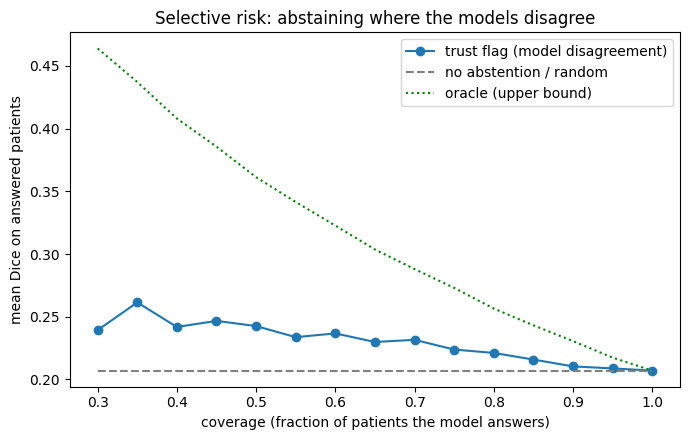

Dice at 100% / 80% / 60% coverage: [np.float64(0.207), np.float64(0.221), np.float64(0.237)]
Disagreement flag at 60% coverage: Dice 0.237 vs 0.207 overall (gain +0.030). Random abstention would gain +0.000 (95% range -0.026 to +0.026); permutation p = 0.011
Trivial rival (abstain when the simple model predicts a SMALL lesion): gain +0.052 at 60% coverage. If this is as big as the disagreement flag, the flag is mostly a lesion-size detector.


In [ ]:
pv = main.pivot_table(index='subject_id', columns='model', values=['dice', 'vol_pred'])
tv = main.groupby('subject_id').agg(vol_true=('vol_true', 'first'), fold=('fold', 'first'))
T = pd.DataFrame({'dice': pv['dice']['xgb'], 'vol_x': pv['vol_pred']['xgb'], 'vol_u': (pv['vol_pred'][best_unet] if best_unet else np.nan)}).join(tv)
T['score'] = (np.log1p(T['vol_x']) - np.log1p(T['vol_u'])).abs()                      # LABEL-FREE disagreement

if best_unet is None: print('No U-Net results yet, so the disagreement flag cannot be computed. Run on a T4 GPU runtime to add them.')
else:
    cov = np.linspace(0.3, 1.0, 15); order = T['score'].sort_values().index; od = T['dice'].sort_values(ascending=False).index
    sel = lambda idx, c: T.loc[idx[:max(3, int(round(c * len(T))))], 'dice'].mean()
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(cov, [sel(order, c) for c in cov], 'o-', label='trust flag (model disagreement)')
    ax.plot(cov, [T['dice'].mean()] * len(cov), '--', color='gray', label='no abstention / random')
    ax.plot(cov, [sel(od, c) for c in cov], ':', color='green', label='oracle (upper bound)')
    ax.set_xlabel('coverage (fraction of patients the model answers)'); ax.set_ylabel('mean Dice on answered patients')
    ax.set_title('Selective risk: abstaining where the models disagree'); ax.legend(); plt.tight_layout(); plt.show()
    print('Dice at 100% / 80% / 60% coverage:', [round(sel(order, c), 3) for c in (1.0, 0.8, 0.6)])
    def gain(score, c=0.6):
        idx = score.sort_values().index; k = max(3, int(round(c * len(T)))); return T.loc[idx[:k], 'dice'].mean() - T['dice'].mean()
    rngp = np.random.default_rng(0); obs = gain(T['score'])
    perm = np.array([gain(pd.Series(rngp.permutation(T['score'].values), index=T.index)) for _ in range(2000)])
    print(f"Disagreement flag at 60% coverage: Dice {T['dice'].mean() + obs:.3f} vs {T['dice'].mean():.3f} overall (gain {obs:+.3f}). Random abstention would gain {perm.mean():+.3f} (95% range {np.percentile(perm, 2.5):+.3f} to {np.percentile(perm, 97.5):+.3f}); permutation p = {(perm >= obs).mean():.3f}")
    print(f"Trivial rival (abstain when the simple model predicts a SMALL lesion): gain {gain(-T['vol_x']):+.3f} at 60% coverage. If this is as big as the disagreement flag, the flag is mostly a lesion-size detector.")

## 13. Interpretability that is *shown*: SHAP + feature-group ablation
SHAP on a fold-0 model says which measurements drive individual voxel calls. The **ablation** retrains the simple model without each feature group — in particular without `position` (is it just memorising anatomy?) and without `mirror` (is the "lopsided" idea actually doing the work?).

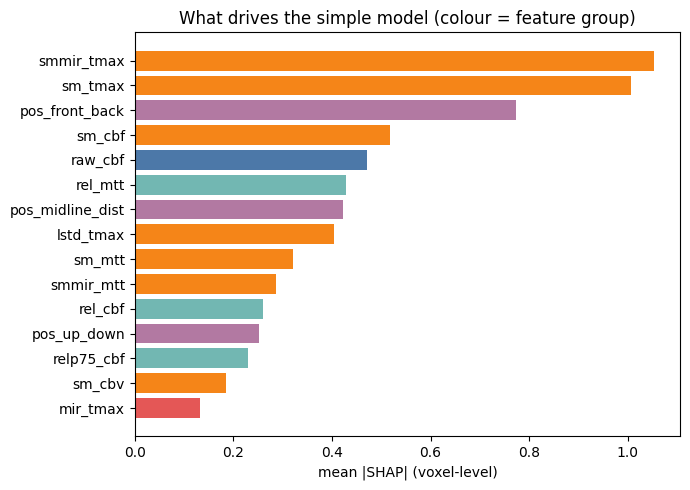

SHAP share by feature group:
context     0.529
mirror      0.049
position    0.194
raw         0.088
relative    0.140
SHAP share of ALL left-right comparison features (any name containing "mir", including the smoothed ones filed under "context"): 0.252

=== Ablation: mean Dice (does the model really need the left-right idea? the position prior?) ===
all features                         0.207
without position                     0.196
without ANY left-right comparison    0.197


In [ ]:
import shap
AB_CK = os.path.join(PROJECT, f'ck_abl_{NB_VER}_ds{DS}' + ('_quick' if QUICK else '') + '.pkl')      # SHAP + ablation are saved, so they are never recomputed
abck = pickle.load(open(AB_CK, 'rb')) if os.path.exists(AB_CK) else dict(imp=None, abl={})
if HAVE_GPU and abck['imp'] is None:
    print('SHAP + ablation are CPU-only work (about an hour). Skipped on a GPU runtime so it does not burn compute units; run this notebook once on a CPU runtime to fill them in.')
else:
    if abck['imp'] is None:
        f0 = FOLDS_TO_RUN[0]; tr0 = [s for s in IDS if FOLD[s] != f0]; te0 = [s for s in IDS if FOLD[s] == f0][:8]
        M0 = fit_gbm(tr0, SEED, BEST_HP['xgb']); rng = np.random.default_rng(0)
        Xs = np.concatenate([FEAT[s]['F'][rng.choice(FEAT[s]['n'], min(1500, FEAT[s]['n']), replace=False)] for s in te0]).astype(np.float32)
        sv = shap.TreeExplainer(M0['model']).shap_values(Xs)
        abck['imp'] = pd.Series(np.abs(sv).mean(0), index=FEAT_NAMES).sort_values(ascending=False); pickle.dump(abck, open(AB_CK, 'wb'))
    imp = abck['imp']
    gcol = {'raw': '#4C78A8', 'relative': '#72B7B2', 'mirror': '#E45756', 'context': '#F58518', 'position': '#B279A2'}
    top = imp.head(15).iloc[::-1]; plt.figure(figsize=(7, 5)); plt.barh(top.index, top.values, color=[gcol[FEAT_GROUP[n]] for n in top.index])
    plt.xlabel('mean |SHAP| (voxel-level)'); plt.title('What drives the simple model (colour = feature group)'); plt.tight_layout(); plt.show()
    print('SHAP share by feature group:'); print((imp.groupby(lambda n: FEAT_GROUP[n]).sum() / imp.sum()).round(3).to_string())
    print('SHAP share of ALL left-right comparison features (any name containing "mir", including the smoothed ones filed under "context"): %.3f' % (imp[[n for n in imp.index if 'mir' in n]].sum() / imp.sum()))
    # NOTE: the "mirror" group above does NOT include the smoothed mirror differences (smmir_*), so it understates how much left-right comparison is used.
    ABL = [('all features', lambda n: True), ('without position', lambda n: FEAT_GROUP[n] != 'position'),
           ('without ANY left-right comparison', lambda n: 'mir' not in n)]
    for label, keep_fn in ABL:
        if label in abck['abl']: continue
        cols = [i for i, n in enumerate(FEAT_NAMES) if keep_fn(n)]; ds = []
        for f in FOLDS_TO_RUN:
            tr = [s for s in IDS if FOLD[s] != f]; te = [s for s in IDS if FOLD[s] == f]; M = fit_gbm(tr, SEED, BEST_HP['xgb'], cols)
            ds += [score_pred(predict_p(M['model'], s, M['cols']) > M['thr'], s)[0] for s in te]
        abck['abl'][label] = float(np.mean(ds)); pickle.dump(abck, open(AB_CK, 'wb')); print('ablation done:', label, round(abck['abl'][label], 3))
    print('\n=== Ablation: mean Dice (does the model really need the left-right idea? the position prior?) ==='); print(pd.Series(abck['abl']).round(3).to_string())

## 13b. Bonus: does predicted damage size track real recovery? (exploratory)
`mrs_3month` is the patient's disability score 3 months later (0 = none ... 6 = death). It is **only used to grade the result, never as a model input.** Question: does the predicted lesion volume say anything about recovery beyond the admission stroke-severity score (`nihss_admission`) and age? Small sample, so this is labelled exploratory and uses cross-validated AUC only.

In [ ]:
from scipy.stats import spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
O = pd.DataFrame([dict(subject_id=s, nihss=META[s].get('nihss_admission'), mrs3=META[s].get('mrs_3month'), age=META[s].get('age')) for s in IDS]).set_index('subject_id')
O = O.apply(pd.to_numeric, errors='coerce').join(T[['vol_x', 'vol_true']]).dropna()
O['poor'] = (O['mrs3'] >= 3).astype(int); O['lx'] = np.log1p(O['vol_x']); O['lt'] = np.log1p(O['vol_true'])
print(len(O), 'patients with all of: severity score, 3-month score, predicted volume | poor outcome (mRS>=3):', int(O['poor'].sum()))
for c, lab in (('nihss', 'admission severity'), ('lt', 'TRUE lesion volume (expert)'), ('lx', 'PREDICTED lesion volume (our model)')):
    r, p = spearmanr(O[c], O['mrs3']); print(f'Spearman with 3-month score | {lab:38s} rho = {r:+.2f} (p = {p:.3f})')
r_v, _ = spearmanr(O['lx'], O['lt']); print(f'Spearman PREDICTED vs TRUE lesion volume (are our volume predictions any good?) rho = {r_v:+.2f}')
if len(O) >= 30 and O['poor'].sum() >= 10 and (1 - O['poor']).sum() >= 10:
    cvs = StratifiedKFold(5, shuffle=True, random_state=0); res = {}
    for name, cols in (('severity + age only', ['nihss', 'age']), ('+ predicted volume', ['nihss', 'age', 'lx']), ('+ true volume (ceiling)', ['nihss', 'age', 'lt'])):
        aucs = [roc_auc_score(O['poor'], cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), O[cols], O['poor'], cv=StratifiedKFold(5, shuffle=True, random_state=r), method='predict_proba')[:, 1]) for r in range(10)]
        res[name] = (np.mean(aucs), np.std(aucs))
    print('\nCross-validated AUC for predicting a poor 3-month outcome (10 repeats):')
    for k, (m, sd) in res.items(): print(f'  {k:28s} {m:.3f} +/- {sd:.3f}')
    print('(Exploratory. If "+ predicted volume" does not beat "severity + age only" by more than the +/- spread, say so.)')
else:
    print('Too few patients in one outcome group for a fair check (normal in QUICK mode).')

127 patients with all of: severity score, 3-month score, predicted volume | poor outcome (mRS>=3): 44
Spearman with 3-month score | admission severity                     rho = +0.26 (p = 0.003)
Spearman with 3-month score | TRUE lesion volume (expert)            rho = +0.38 (p = 0.000)
Spearman with 3-month score | PREDICTED lesion volume (our model)    rho = +0.00 (p = 0.959)
Spearman PREDICTED vs TRUE lesion volume (are our volume predictions any good?) rho = +0.22

Cross-validated AUC for predicting a poor 3-month outcome (10 repeats):
  severity + age only          0.660 +/- 0.008
  + predicted volume           0.658 +/- 0.010
  + true volume (ceiling)      0.746 +/- 0.011
(Exploratory. If "+ predicted volume" does not beat "severity + age only" by more than the +/- spread, say so.)


## 14. Hero figure + the numbers for the slide
Auto-assembled from the saved results: (a) head-to-head with CIs, (b) data-efficiency, (c) unseen-site gap. Use whichever of the three outcomes the data supports; do not pick the story first.

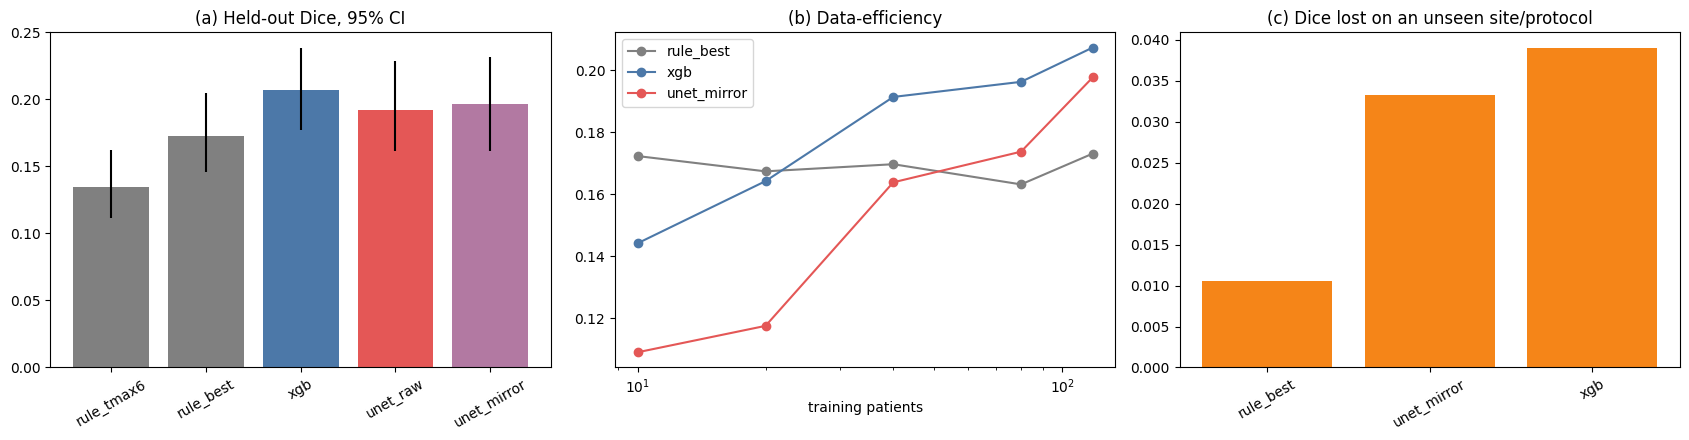


HEADLINE FILL-IN (choose the sentence the data supports):
A) "With fewer than N* labelled patients, an interpretable model beats a U-Net; above N* the U-Net wins by X Dice."
B) "An interpretable model is within +/-0.05 Dice of a U-Net at every training size."
C) "The U-Net wins by X Dice at every size - the simple features miss Z, and the trust flag catches W% of the failures."
D) "A single tuned threshold is about as good as every learned model: complexity buys little on this task."


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
mm = main[main.model.isin(['rule_tmax6', 'rule_best', 'xgb', 'unet_raw', 'unet_mirror'])]; rng = np.random.default_rng(1)
names = [m for m in ['rule_tmax6', 'rule_best', 'xgb', 'unet_raw', 'unet_mirror'] if m in set(mm.model)]; ms, errs = [], []
COL = {'rule_tmax6': 'gray', 'rule_best': 'gray', 'xgb': '#4C78A8', 'unet_raw': '#E45756', 'unet_mirror': '#B279A2'}
for m in names:
    v = pat_dice(mm, m).values; bs = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(1000)]; ms.append(v.mean()); errs.append([v.mean() - np.percentile(bs, 2.5), np.percentile(bs, 97.5) - v.mean()])
axs[0].bar(names, ms, yerr=np.array(errs).T, color=[COL[m] for m in names]); axs[0].set_title('(a) Held-out Dice, 95% CI'); axs[0].tick_params(axis='x', rotation=30)
for m, c in zip(DE_MODELS, ['gray', '#4C78A8', '#E45756', '#B279A2']):
    g = curve[curve.model == m].groupby('n_lab')['dice'].mean(); axs[1].plot(g.index, g.values, 'o-', color=c, label=m)
axs[1].set_xscale('log'); axs[1].set_title('(b) Data-efficiency'); axs[1].set_xlabel('training patients'); axs[1].legend()
if LOSO:
    axs[2].bar(g2.index, g2['drop'], color='#F58518'); axs[2].set_title('(c) Dice lost on an unseen site/protocol'); axs[2].tick_params(axis='x', rotation=30)
else: axs[2].text(0.1, 0.5, 'no usable site groups', transform=axs[2].transAxes); axs[2].axis('off')
plt.tight_layout(); plt.savefig(os.path.join(PROJECT, 'hero_figure.png'), dpi=200); plt.show()

print('\nHEADLINE FILL-IN (choose the sentence the data supports):')
print('A) "With fewer than N* labelled patients, an interpretable model beats a U-Net; above N* the U-Net wins by X Dice."')
print('B) "An interpretable model is within +/-0.05 Dice of a U-Net at every training size."')
print('C) "The U-Net wins by X Dice at every size - the simple features miss Z, and the trust flag catches W% of the failures."')
print('D) "A single tuned threshold is about as good as every learned model: complexity buys little on this task."')

## Appendix — what the Week-2 notebook still contributes
Keep its Level-1/Level-2 outputs as a **sanity-check slide**: every model, including a single feature, reaches AUC ~0.96-0.98 at "which hemisphere", which is exactly why the project moved to voxel-level locating where the answer is not given away by construction. Also keep: the orientation-standardisation story (47 flipped scans) and the leakage guard (`assert not any(n.startswith(('lesion','les_','reg_')) ...)`).

**Optional stretch (only if `OUTCOME_COL` exists):** does predicted lesion volume / the trust flag carry information about 90-day outcome? Decide deliberately — it changes the stated scope.

# Cell A: pin the package versions (copy the printout into requirements.txt)



In [ ]:
import importlib.metadata as imd, sys
print('python', sys.version.split()[0])
for p in ['nibabel', 'pyarrow', 'pandas', 'numpy', 'scipy', 'scikit-learn', 'xgboost', 'shap', 'torch', 'matplotlib', 'tqdm', 'psutil']:
    try: print(f'{p}=={imd.version(p)}')
    except Exception: print(f'# {p}: not installed in this session')

python 3.13.18
nibabel==5.4.2
pyarrow==23.0.1
pandas==2.2.3
numpy==2.1.3
scipy==1.16.3
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.54.1
torch==2.11.0+cpu
matplotlib==3.10.0
tqdm==4.67.3
psutil==5.9.5


# Cell B: does the "equivalent" verdict survive a stricter margin?

In [ ]:
print('=== xgb minus U-Net, paired bootstrap over patients, verdict at three margins ===')
for deep in [d for d in ('unet_raw', 'unet_mirror') if d in set(main.model)]:
    m, lo, hi = paired_ci(pat_dice(main, 'xgb'), pat_dice(main, deep))
    print(f'full data, xgb - {deep}: {m:+.3f} [{lo:+.3f}, {hi:+.3f}]')
    for delta in (0.02, 0.03, 0.05): print(f'    margin +/-{delta:.2f}: {verdict(lo, hi, delta)}')
if best_unet:
    print(f'\nBy training size, xgb - {best_unet}:')
    for n in sorted(curve['n_lab'].unique()):
        a = curve[(curve.model == 'xgb') & (curve.n_lab == n)].set_index('subject_id')['dice']
        b = curve[(curve.model == best_unet) & (curve.n_lab == n)].set_index('subject_id')['dice']; k = a.index.intersection(b.index)
        m, lo, hi = paired_ci(a[k], b[k])
        print(f'  n={n:4d} {m:+.3f} [{lo:+.3f}, {hi:+.3f}] | ' + ' | '.join(f'+/-{d:.2f}: {verdict(lo, hi, d).split(" (")[0]}' for d in (0.02, 0.03, 0.05)))

=== xgb minus U-Net, paired bootstrap over patients, verdict at three margins ===
full data, xgb - unet_raw: +0.015 [-0.005, +0.035]
    margin +/-0.02: NON-INFERIOR (simple >= deep - delta)
    margin +/-0.03: NON-INFERIOR (simple >= deep - delta)
    margin +/-0.05: EQUIVALENT (CI inside +/-delta)
full data, xgb - unet_mirror: +0.011 [-0.008, +0.030]
    margin +/-0.02: NON-INFERIOR (simple >= deep - delta)
    margin +/-0.03: NON-INFERIOR (simple >= deep - delta)
    margin +/-0.05: EQUIVALENT (CI inside +/-delta)

By training size, xgb - unet_mirror:
  n=  10 +0.035 [+0.014, +0.058] | +/-0.02: NON-INFERIOR | +/-0.03: NON-INFERIOR | +/-0.05: NON-INFERIOR
  n=  20 +0.047 [+0.025, +0.069] | +/-0.02: SIMPLE BETTER | +/-0.03: NON-INFERIOR | +/-0.05: NON-INFERIOR
  n=  40 +0.028 [+0.007, +0.050] | +/-0.02: NON-INFERIOR | +/-0.03: NON-INFERIOR | +/-0.05: EQUIVALENT
  n=  80 +0.022 [+0.004, +0.041] | +/-0.02: NON-INFERIOR | +/-0.03: NON-INFERIOR | +/-0.05: EQUIVALENT
  n= 118 +0.010 [-0.01

# Cell C: show the brain mask on three patients (turns a hidden flaw into an explained limitation)

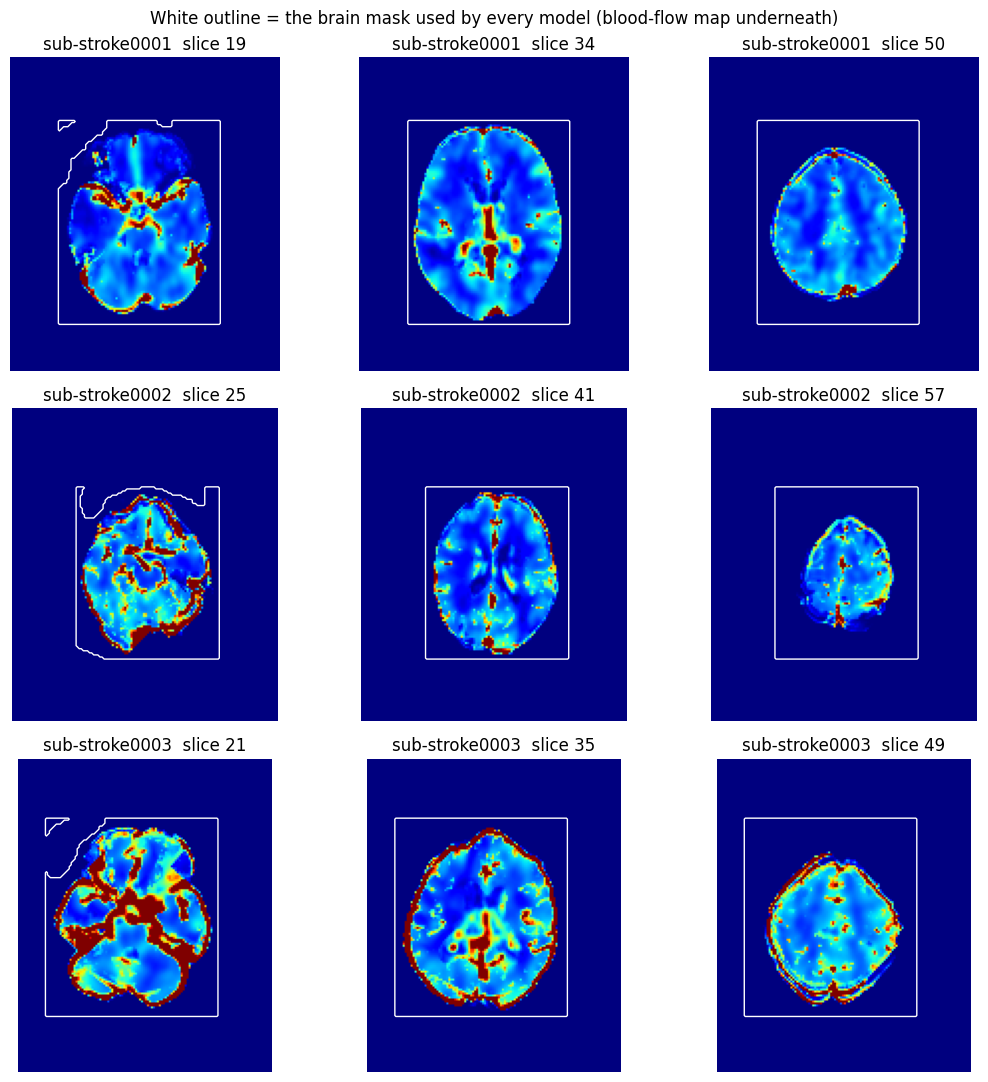

Mean mask volume: 2671 mL | a real adult brain is roughly 1,300 mL


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
for r, sid in enumerate(IDS[:3]):
    g = get(sid); zs = np.nonzero(g['brain'].any(axis=(0, 1)))[0]; span = zs.max() - zs.min()
    for c, z in enumerate((zs.min() + span // 5, (zs.min() + zs.max()) // 2, zs.max() - span // 5)):
        axes[r, c].imshow(g['arr'][0][:, :, z].T.astype(np.float32), cmap='jet', origin='lower', vmin=0, vmax=60)
        axes[r, c].contour(g['brain'][:, :, z].T.astype(float), levels=[0.5], colors='white', linewidths=1)
        axes[r, c].set_title(f'{sid}  slice {z}'); axes[r, c].axis('off')
plt.suptitle('White outline = the brain mask used by every model (blood-flow map underneath)'); plt.tight_layout(); plt.show()
print('Mean mask volume: %.0f mL | a real adult brain is roughly 1,300 mL' % np.mean([FEAT[s]['n'] * FEAT[s]['vox_ml'] for s in IDS]))

# Cell D: the dropped "satellite lesion" analysis (are lesions in separate pieces harder?)

In [ ]:
import scipy.ndimage as ndi
rows = []
for s in IDS:
    m = get(s)['mask']; lab, n = ndi.label(m)
    if n == 0: continue
    sizes = np.bincount(lab.ravel())[1:]; vm = FEAT[s]['vox_ml']
    rows.append(dict(subject_id=s, n_pieces=n, total_ml=sizes.sum() * vm, satellite_frac=1 - sizes.max() / sizes.sum()))
S = pd.DataFrame(rows).set_index('subject_id'); S['dice'] = main[main.model == 'xgb'].groupby('subject_id')['dice'].mean().reindex(S.index)
S['has_satellites'] = S['satellite_frac'] >= 0.10
print(f'{int(S.has_satellites.sum())} of {len(S)} patients have >=10% of their lesion in pieces separate from the main lesion (median pieces per patient: {int(S.n_pieces.median())})')
print('\nxgb Dice by satellite status:'); print(S.groupby('has_satellites')['dice'].agg(['mean', 'count']).round(3).to_string())
big = S[S.total_ml >= S.total_ml.median()]
print('\nWithin larger lesions only (to separate the satellite effect from lesion size):'); print(big.groupby('has_satellites')['dice'].agg(['mean', 'count']).round(3).to_string())

76 of 146 patients have >=10% of their lesion in pieces separate from the main lesion (median pieces per patient: 10)

xgb Dice by satellite status:
                 mean  count
has_satellites              
False           0.317     70
True            0.109     76

Within larger lesions only (to separate the satellite effect from lesion size):
                 mean  count
has_satellites              
False           0.379     53
True            0.184     20


# Cell E: is the lesion-size rule really a better trust flag than model disagreement?

In [ ]:
if best_unet is None: print('Needs the U-Net results (they reload from the checkpoints on Run all).')
else:
    d, s_dis, s_size = T['dice'].values, T['score'].values, -T['vol_x'].values
    def gain(sc, i, c=0.6):
        k = max(3, int(round(c * len(i)))); o = np.argsort(sc[i], kind='stable')[:k]; return d[i][o].mean() - d[i].mean()
    rng = np.random.default_rng(0); n = len(T); allidx = np.arange(n)
    diffs = np.array([gain(s_size, i) - gain(s_dis, i) for i in (rng.integers(0, n, n) for _ in range(2000))]); lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f'Gain at 60% coverage: size rule {gain(s_size, allidx):+.3f} vs disagreement flag {gain(s_dis, allidx):+.3f}')
    print(f'Difference (size minus disagreement): {diffs.mean():+.3f}, 95% CI {lo:+.3f} to {hi:+.3f}')
    print('Interval excludes 0 -> the size rule is genuinely better. Includes 0 -> call the two flags comparable.')

Gain at 60% coverage: size rule +0.052 vs disagreement flag +0.030
Difference (size minus disagreement): +0.022, 95% CI -0.005 to +0.049
Interval excludes 0 -> the size rule is genuinely better. Includes 0 -> call the two flags comparable.


# Cell F (optional, about 1 to 1.5 hours): extra random draws of the training patients for the simple model and the threshold

Stress-tests the n = 10 to 40 findings (the least certain part of the headline). The U-Net stays at one draw, because it needs a GPU.

In [ ]:
SEEDS_EXTRA = (1, 2)       # extra random draws (the main run used one draw per fold)
N_EXTRA = [10, 20, 40]     # n = 80 is slow and adds little
CKX = os.path.join(PROJECT, f'ck_extra_seeds_{NB_VER}_ds{DS}.pkl')
ckx = pickle.load(open(CKX, 'rb')) if os.path.exists(CKX) else dict(rows=[], done=set())
for f in FOLDS_TO_RUN:
    tr_all = [s for s in IDS if FOLD[s] != f]; te = [s for s in IDS if FOLD[s] == f]
    for n in N_EXTRA:
        for seed in SEEDS_EXTRA:
            rng = np.random.default_rng(100 * seed + f); tr = list(rng.choice(tr_all, n, replace=False))
            for name in ('rule_best', 'xgb'):
                if (f, n, seed, name) in ckx['done']: continue
                rows, _ = run_model(name, tr, te, seed, hp=BEST_HP.get(name))
                for r in rows: r.update(model=name, fold=f, n_lab=n, seed=seed)
                ckx['rows'] += rows; ckx['done'].add((f, n, seed, name)); pickle.dump(ckx, open(CKX, 'wb'))
    print('fold', f, 'done')
X = pd.DataFrame(ckx['rows']); orig = de[de.model.isin(['rule_best', 'xgb']) & de.n_lab.isin(N_EXTRA)][['model', 'n_lab', 'subject_id', 'dice', 'seed']]
pp = pd.concat([orig, X[['model', 'n_lab', 'subject_id', 'dice', 'seed']]]).groupby(['model', 'n_lab', 'subject_id'])['dice'].mean().reset_index()
print(f'\nxgb minus best single threshold, averaged over {1 + len(SEEDS_EXTRA)} random draws of the training patients:')
for n in N_EXTRA:
    a = pp[(pp.model == 'xgb') & (pp.n_lab == n)].set_index('subject_id')['dice']; b = pp[(pp.model == 'rule_best') & (pp.n_lab == n)].set_index('subject_id')['dice']; k = a.index.intersection(b.index)
    m, lo, hi = paired_ci(a[k], b[k]); print(f'  n={n:3d}: {m:+.3f} [{lo:+.3f}, {hi:+.3f}] -> ' + ('xgb ahead' if lo > 0 else 'xgb behind' if hi < 0 else 'tied'))

fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done

xgb minus best single threshold, averaged over 3 random draws of the training patients:
  n= 10: -0.022 [-0.038, -0.008] -> xgb behind
  n= 20: -0.003 [-0.015, +0.008] -> tied
  n= 40: +0.017 [+0.004, +0.032] -> xgb ahead


# Cell G (optional, about 40 minutes): ablation with confidence intervals
Re-runs the "all features" and "without any left-right comparison" models keeping per-patient scores, so the 0.010 difference gets an interval. It does not touch the earlier ablation results.

In [ ]:
AB2 = os.path.join(PROJECT, f'ck_abl_perpatient_{NB_VER}_ds{DS}.pkl')
ab2 = pickle.load(open(AB2, 'rb')) if os.path.exists(AB2) else {}
CFG = [('all features', lambda n: True), ('without ANY left-right comparison', lambda n: 'mir' not in n)]   # add ('without position', lambda n: FEAT_GROUP[n] != 'position') for a third (+20 min)
for label, keep_fn in CFG:
    if label in ab2: continue
    cols = [i for i, n in enumerate(FEAT_NAMES) if keep_fn(n)]; res = {}
    for f in FOLDS_TO_RUN:
        tr = [s for s in IDS if FOLD[s] != f]; te = [s for s in IDS if FOLD[s] == f]; M = fit_gbm(tr, SEED, BEST_HP['xgb'], cols)
        for s in te: res[s] = score_pred(predict_p(M['model'], s, M['cols']) > M['thr'], s)[0]
    ab2[label] = pd.Series(res); pickle.dump(ab2, open(AB2, 'wb')); print('done:', label, round(ab2[label].mean(), 3))
base = ab2['all features']
for label in [l for l, _ in CFG[1:]]:
    m, lo, hi = paired_ci(base, ab2[label].reindex(base.index))
    print(f'{label}: change in mean Dice {-m:+.3f} (95% CI {-hi:+.3f} to {-lo:+.3f})   [negative = the model got worse]')

without ANY left-right comparison: change in mean Dice -0.010 (95% CI -0.017 to -0.003)   [negative = the model got worse]


# Cell H: sensitivity and precision for every model (the original statement asked for sensitivity)

Derived exactly from the stored Dice and volumes (Dice = 2 x overlap / (predicted + true), so the overlap, and from it sensitivity and precision, can be recovered). No retraining. Voxel-level ROC-AUC needs saved probabilities and is not available.

In [ ]:
m = main.copy()
m['tp'] = m['dice'] * (m['vol_pred'] + m['vol_true']) / 2
m['sens'] = (m['tp'] / m['vol_true']).where(m['vol_true'] > 0); m['prec'] = (m['tp'] / m['vol_pred']).where(m['vol_pred'] > 0)
g = m.groupby('model')
out = pd.DataFrame({'mean Dice': g['dice'].mean(), 'sensitivity (mean of patients)': g['sens'].mean(), 'precision (mean of patients)': g['prec'].mean(),
                    'sensitivity (all voxels pooled)': g['tp'].sum() / g['vol_true'].sum(), 'precision (all voxels pooled)': g['tp'].sum() / g['vol_pred'].sum()}).sort_values('mean Dice', ascending=False)
print(out.round(3).to_string())
print('\nSensitivity = share of the expert-marked lesion the model found. Precision = share of what the model marked that really was lesion.')

             mean Dice  sensitivity (mean of patients)  precision (mean of patients)  sensitivity (all voxels pooled)  precision (all voxels pooled)
model                                                                                                                                               
xgb              0.207                           0.386                         0.216                            0.430                          0.257
unet_mirror      0.197                           0.335                         0.224                            0.438                          0.278
unet_raw         0.192                           0.319                         0.226                            0.464                          0.300
rule_best        0.173                           0.383                         0.166                            0.467                          0.177
rule_tmax6       0.135                           0.465                         0.103                      

# Cell I: performance by sex, age and admission stroke severity
Groups can differ just because their lesions differ in size, so the median lesion size is printed too. Small groups: read as a check, not a finding.

In [ ]:
Q = pd.DataFrame([dict(subject_id=s, age=META[s].get('age'), sex=META[s].get('sex'), nihss=META[s].get('nihss_admission')) for s in IDS]).set_index('subject_id')
Q['age'] = pd.to_numeric(Q['age'], errors='coerce'); Q['nihss'] = pd.to_numeric(Q['nihss'], errors='coerce')
X_ = main[main.model == 'xgb'].groupby('subject_id').agg(dice=('dice', 'mean'), lesion_ml=('vol_true', 'first'))
Q = Q.join(X_)
Q['age_group'] = pd.qcut(Q['age'].rank(method='first'), 3, labels=['youngest third', 'middle third', 'oldest third'])
Q['severity'] = pd.qcut(Q['nihss'].rank(method='first'), 3, labels=['mildest third', 'middle third', 'most severe third'])
for col in ('sex', 'age_group', 'severity'):
    t = Q.groupby(col, observed=True).agg(mean_dice=('dice', 'mean'), median_lesion_mL=('lesion_ml', 'median'), patients=('dice', 'count')).round(3)
    print(f'--- interpretable model, Dice by {col} ---'); print(t.to_string()); print()
print('Age ranges:', Q.groupby('age_group', observed=True)['age'].agg(['min', 'max']).to_dict('index'))

--- interpretable model, Dice by sex ---
     mean_dice  median_lesion_mL  patients
sex                                       
F        0.216            14.172        72
M        0.200            11.602        74

--- interpretable model, Dice by age_group ---
                mean_dice  median_lesion_mL  patients
age_group                                            
youngest third      0.220            15.703        49
middle third        0.207            13.906        49
oldest third        0.194             9.249        49

--- interpretable model, Dice by severity ---
                   mean_dice  median_lesion_mL  patients
severity                                                
mildest third          0.159             8.262        48
middle third           0.178            12.120        47
most severe third      0.294            30.768        48

Age ranges: {'youngest third': {'min': 29.939725875854492, 'max': 66.0}, 'middle third': {'min': 66.0, 'max': 80.0}, 'oldest third': {'m

# Cell J: does the order change when large lesions count more? (pooled Dice with intervals)
Cell H's pooled sensitivity and precision imply a higher pooled Dice for the U-Nets than for the interpretable model, the opposite of mean patient Dice. This tests it. Stored results only; no retraining. Run after Run all, same session.

In [ ]:
m = main.copy()
m['tp'] = m['dice'] * (m['vol_pred'] + m['vol_true']) / 2
P = m.groupby(['model', 'subject_id'])[['tp', 'vol_pred', 'vol_true']].sum()
def pooled(model, idx):
    d = P.loc[model].reindex(idx)
    return 2 * d['tp'].sum() / (d['vol_pred'].sum() + d['vol_true'].sum())
ids = np.array(sorted(set(m.subject_id))); rng = np.random.default_rng(0)
boots = [rng.choice(ids, len(ids)) for _ in range(2000)]
print('Pooled Dice (all voxels together; big lesions dominate):')
for mod in P.index.get_level_values(0).unique(): print(f'  {mod:12s} {pooled(mod, ids):.3f}')
for deep in [d for d in ('unet_mirror', 'unet_raw', 'rule_best') if d in P.index.get_level_values(0)]:
    obs = pooled('xgb', ids) - pooled(deep, ids)
    diffs = np.array([pooled('xgb', i) - pooled(deep, i) for i in boots]); lo, hi = np.percentile(diffs, [2.5, 97.5])
    print(f'xgb - {deep}: {obs:+.3f} [{lo:+.3f}, {hi:+.3f}] ->', 'xgb ahead' if lo > 0 else 'xgb behind' if hi < 0 else 'tied (CI includes 0)')
print('Compare with mean patient Dice: xgb - unet_mirror +0.011, xgb - unet_raw +0.015.')

Pooled Dice (all voxels together; big lesions dominate):
  rule_best    0.257
  rule_core    0.196
  rule_tmax6   0.177
  unet_mirror  0.340
  unet_raw     0.365
  xgb          0.322
xgb - unet_mirror: -0.018 [-0.047, +0.014] -> tied (CI includes 0)
xgb - unet_raw: -0.043 [-0.074, -0.010] -> xgb behind
xgb - rule_best: +0.065 [+0.040, +0.088] -> xgb ahead
Compare with mean patient Dice: xgb - unet_mirror +0.011, xgb - unet_raw +0.015.
